<a href="https://colab.research.google.com/github/am2497/CRM_CWK1/blob/main/CRM1_Codes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
# TASK 1: Data Preparation and Feature Engineering

In [42]:
# 1.1	Ticker selection and Data Acquisition

!pip install -q yfinance
import pandas as pd, numpy as np, yfinance as yf
import datetime as dt, sys, json, sklearn, scipy
from IPython.display import display

# 1. Parameters, retrieval date and package version
RETRIEVAL_DATE = dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
START, END, BENCH = '2021-01-01', '2025-01-01', '^GSPC'
URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

versions = {'python': sys.version.split()[0], 'pandas': pd.__version__,
            'numpy': np.__version__, 'yfinance': yf.__version__,
            'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}
print('Retrieval date:', RETRIEVAL_DATE)
print('Package versions:', versions)

# 2. Extract and store S&P 500 Ticker List from Wiki
tables = pd.read_html(URL, storage_options={'User-Agent':'Mozilla/5.0'})
sp500_df = tables[0].copy()

sp500_df['Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
sp500_df['Date added'] = pd.to_datetime(sp500_df['Date added'], errors='coerce')
sp500_df['Retrieved'] = RETRIEVAL_DATE
sp500_df.to_csv('sp500_constituents.csv', index=False)

tickers = sp500_df['Ticker'].to_list()
print(f'\nTickers extracted: {len(tickers)} (unique: {sp500_df["Ticker"].nunique()})')

# 3. Survivorship-bias evidence
changes = tables[1].copy()
changes.to_csv('sp500_changes.csv', index=False)

joined_late = sp500_df[sp500_df['Date added'] >= START].sort_values('Date added')
print(f'Current constituents added on/after {START}: {len(joined_late)}')

# 4. Download daily prices, adjusted prices, volume and benchmark
raw = yf.download(tickers + [BENCH], start=START, end=END,
                  auto_adjust=False,
                  actions=True,
                  threads=True, progress=True)

fields = [f for f in ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume',
                      'Dividends', 'Stock Splits']
          if f in raw.columns.get_level_values(0)]

try:
  long = raw[fields].stack(level=1, future_stack=True)
except TypeError:
  long = raw[fields].stack(level=1, dropna=False)
long = long.rename_axis(['Date', 'Ticker']).reset_index()

long.to_parquet('raw_prices_2021_2024.parquet', index=False)

# 5. Coverage Check
cov = (long.dropna(subset=['Adj Close']).groupby('Ticker')['Date']
           .agg(first_date='min', last_date='max', n_days='count'))
cov = cov.reindex(tickers + [BENCH])

bench_first, bench_last, bench_n = cov.loc[BENCH]
no_data     = cov[cov['n_days'].isna()].index.tolist()
late_start  = cov[cov['first_date'] > bench_first].index.tolist()
early_end   = cov[cov['last_date'] < bench_last].index.tolist()
full_hist   = cov[cov['n_days'] == bench_n].index.drop(BENCH, errors='ignore')

cov.to_csv('download_coverage.csv')

# 6. Table 1.1a — Acquisition summary
files = ['sp500_constituents.csv', 'sp500_changes.csv', 'raw_prices_2021_2024.parquet',
         'download_coverage.csv', 'acquisition_exclusion_log.csv', 'acquisition_metadata.json']

summary = pd.DataFrame({
    'Item': ['Ticker source', 'Retrieval date', 'Price source / library', 'Study period',
             'Benchmark', 'Fields downloaded', 'Tickers extracted', 'Benchmark trading days',
             'Shares with full history', 'Shares with partial history (listed after start)',
             'Shares with no data', 'Shares ending before benchmark',
             'Constituents added on/after 2021-01-01', 'Saved files'],
    'Value': [URL, RETRIEVAL_DATE, f'Yahoo Finance via yfinance {yf.__version__} (auto_adjust=False)',
              f'{START} to {END} (end exclusive); actual {bench_first.date()} – {bench_last.date()}',
              BENCH, ', '.join(fields), len(tickers), int(bench_n), len(full_hist),
              len(late_start), len(no_data), len(early_end), len(joined_late), ', '.join(files)]})
print('\nTable 1.1a — Data acquisition summary')
display(summary.style.hide(axis='index').set_properties(**{'text-align': 'left'})
        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}]))

# 7. Table 1.1b — Coverage and exclusion log
log = (cov.loc[no_data + late_start]
          .join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector', 'Date added']])
          .reset_index().rename(columns={'index': 'Ticker'}))
log['Status'] = np.where(log['Ticker'].isin(no_data), 'Excluded', 'Retained – review in 1.2')
log['Reason'] = np.where(log['Ticker'].isin(no_data),
                         'No Yahoo price data in 2021–2024 (listed/spun off after study period)',
                         'Listed after study start – partial history')
log['first_date'] = pd.to_datetime(log['first_date']).dt.date
log['Date added'] = pd.to_datetime(log['Date added']).dt.date
log['n_days'] = log['n_days'].astype('Int64')
log = log[['Ticker', 'Security', 'GICS Sector', 'Date added', 'first_date', 'n_days', 'Status', 'Reason']]
log.columns = ['Ticker', 'Company', 'Sector', 'Added to S&P 500', 'First price date',
               'Trading days', 'Status', 'Reason']
log.to_csv('acquisition_exclusion_log.csv', index=False)
print('\nTable 1.1b — Coverage and exclusion log')
display(log.style.hide(axis='index'))

# 8. Acquisition metadata (for reproducibility / GitHub)
metadata = {
    'retrieval_date': RETRIEVAL_DATE, 'ticker_source': URL,
    'price_source': 'Yahoo Finance via yfinance', 'start': START, 'end_exclusive': END,
    'benchmark': BENCH, 'auto_adjust': False, 'fields': fields,
    'n_tickers_wikipedia': len(tickers), 'n_joined_on_or_after_start': len(joined_late),
    'no_data': no_data, 'late_start': late_start, 'early_end': early_end,
    'benchmark_trading_days': int(bench_n), 'package_versions': versions, 'files': files}
with open('acquisition_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2, default=str)
print('\nSaved:', files)

Retrieval date: 2026-11-08 17:38 UTC
Package versions: {'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'scikit-learn': '1.6.1', 'scipy': '1.16.3'}

Tickers extracted: 503 (unique: 503)
Current constituents added on/after 2021-01-01: 89


[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'SNDK', 'FDXF', 'HONA', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')



Table 1.1a — Data acquisition summary


Item,Value
Ticker source,https://en.wikipedia.org/wiki/List_of_S%26P_500_companies
Retrieval date,2026-11-08 17:38 UTC
Price source / library,Yahoo Finance via yfinance 0.2.66 (auto_adjust=False)
Study period,2021-01-01 to 2025-01-01 (end exclusive); actual 2021-01-04 – 2024-12-31
Benchmark,^GSPC
Fields downloaded,"Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits"
Tickers extracted,503
Benchmark trading days,1005
Shares with full history,488
Shares with partial history (listed after start),10



Table 1.1b — Coverage and exclusion log


Ticker,Company,Sector,Added to S&P 500,First price date,Trading days,Status,Reason
FDXF,FedEx Freight,Industrials,2026-06-01,NaT,,Excluded,No Yahoo price data in 2021–2024 (listed/spun off after study period)
HONA,Honeywell Aerospace,Industrials,2026-06-29,NaT,,Excluded,No Yahoo price data in 2021–2024 (listed/spun off after study period)
Q,Qnity Electronics,Information Technology,2025-11-03,NaT,,Excluded,No Yahoo price data in 2021–2024 (listed/spun off after study period)
SNDK,Sandisk,Information Technology,2025-11-28,NaT,,Excluded,No Yahoo price data in 2021–2024 (listed/spun off after study period)
VYLR,Vylor,Consumer Staples,2026-10-01,NaT,,Excluded,No Yahoo price data in 2021–2024 (listed/spun off after study period)
APP,AppLovin,Communication Services,2025-09-22,2021-04-15,935,Retained – review in 1.2,Listed after study start – partial history
COIN,Coinbase,Financials,2025-05-19,2021-04-14,936,Retained – review in 1.2,Listed after study start – partial history
CEG,Constellation Energy,Utilities,2022-02-02,2022-01-19,742,Retained – review in 1.2,Listed after study start – partial history
EXE,Expand Energy,Energy,2025-03-24,2021-02-10,979,Retained – review in 1.2,Listed after study start – partial history
GEHC,GE HealthCare,Health Care,2023-01-04,2022-12-15,513,Retained – review in 1.2,Listed after study start – partial history



Saved: ['sp500_constituents.csv', 'sp500_changes.csv', 'raw_prices_2021_2024.parquet', 'download_coverage.csv', 'acquisition_exclusion_log.csv', 'acquisition_metadata.json']


In [43]:
# TASK 1.2 — Data validation and alignment (Daily checks)
from IPython.display import display

# Each ticker's active window = first to last valid price
d = long.join(cov[['first_date', 'last_date']], on='Ticker').sort_values(['Ticker', 'Date'])
d = d[~d['Ticker'].isin(no_data)]
act = d[d['Date'].between(d['first_date'], d['last_date'])].copy()

# 1. Duplicate dates
dup = act.duplicated(['Ticker', 'Date'])
# 2. Missing values inside active window
miss = act[['Close', 'Adj Close', 'Volume']].isna().any(axis=1)
# 3. Non-positive prices
nonpos = (act['Close'] <= 0) | (act['Adj Close'] <= 0)
# 4. Volume errors
vol_neg  = act['Volume'] < 0
vol_zero = (act['Volume'] == 0) & (act['Ticker'] != BENCH)
# 5. Corporate actions
splits = act.loc[act['Stock Splits'] > 0, ['Ticker', 'Date', 'Stock Splits']]
n_div  = int((act['Dividends'] > 0).sum())
adj_gt_close = act['Adj Close'] > act['Close'] * 1.001          # adjusted should never exceed close
act['ret'] = act.groupby('Ticker')['Adj Close'].pct_change(fill_method=None)
big = act.loc[act['ret'].abs() > 0.40, ['Ticker', 'Date', 'Close', 'Adj Close', 'ret']]
big = big[~big.set_index(['Ticker', 'Date']).index.isin(splits.set_index(['Ticker', 'Date']).index)]

# Validation summary
def row(check, rule, mask_or_df, action):
    if isinstance(mask_or_df, pd.Series):
        n, t = int(mask_or_df.sum()), act.loc[mask_or_df, 'Ticker'].nunique()
    else:
        n, t = len(mask_or_df), mask_or_df['Ticker'].nunique()
    return [check, rule, n, t, 'Passed' if n == 0 else action]

checks = pd.DataFrame([
    row('Duplicate dates', 'Same ticker and date appears more than once', dup, 'Keep first, log'),
    row('Missing values', 'NaN Close / Adj Close / Volume inside active window', miss, 'Not filled; logged'),
    row('Non-positive prices', 'Close or Adj Close ≤ 0', nonpos, 'Exclude ticker'),
    row('Negative volume', 'Volume < 0', vol_neg, 'Exclude ticker'),
    row('Zero volume', 'Volume = 0 on a trading day', vol_zero, 'Review (halt or data error)'),
    row('Adj Close > Close', 'Adjusted price above close', adj_gt_close, 'Review'),
    row('Stock splits', 'Stock Splits > 0', splits, 'Expected – Yahoo Close/Volume are split-adjusted'),
    row('Large daily moves', '|daily return| > 40% not on a split date', big, 'Review against news'),
], columns=['Check', 'Rule', 'Rows flagged', 'Tickers affected', 'Action'])

print(f'Tickers checked: {act["Ticker"].nunique()} (incl. {BENCH}) | Rows checked: {len(act):,} | Dividend events: {n_div:,}')
print('\nTable 1.2a — Daily validation checks')
display(checks.style.hide(axis='index'))

print('\nStock splits found:')
display(splits.style.hide(axis='index'))
print('\nLarge daily moves (not on split dates):')
display(big.style.hide(axis='index').format({'ret': '{:.1%}'}))

# For GitHub
checks.to_csv('validation_checks.csv', index=False)
splits.to_csv('validation_splits.csv', index=False)
big.to_csv('validation_large_moves.csv', index=False)

# Trim pre-NYSE-listing history (zero-volume proxy data) for FERG and SW
zv_end = act[vol_zero].groupby('Ticker')['Date'].max()
for t, last_zero in zv_end.items():
    act = act[~((act['Ticker'] == t) & (act['Date'] <= last_zero))]
    print(f'{t}: history now starts {act.loc[act["Ticker"] == t, "Date"].min().date()} '
          f'({(act["Ticker"] == t).sum()} trading days)')
print('Zero-volume rows left:', int(((act['Volume'] == 0) & (act['Ticker'] != BENCH)).sum()))
pd.DataFrame({'Ticker': zv_end.index, 'Trimmed up to': zv_end.values,
              'Reason': ['Pre-NYSE listing: zero-volume proxy history'] * len(zv_end)}
            ).to_csv('validation_trimmed_histories.csv', index=False)

Tickers checked: 499 (incl. ^GSPC) | Rows checked: 497,309 | Dividend events: 6,086

Table 1.2a — Daily validation checks


Check,Rule,Rows flagged,Tickers affected,Action
Duplicate dates,Same ticker and date appears more than once,0,0,Passed
Missing values,NaN Close / Adj Close / Volume inside active window,0,0,Passed
Non-positive prices,Close or Adj Close ≤ 0,0,0,Passed
Negative volume,Volume < 0,0,0,Passed
Zero volume,Volume = 0 on a trading day,451,2,Review (halt or data error)
Adj Close > Close,Adjusted price above close,0,0,Passed
Stock splits,Stock Splits > 0,61,53,Expected – Yahoo Close/Volume are split-adjusted
Large daily moves,|daily return| > 40% not on a split date,11,7,Review against news



Stock splits found:


Ticker,Date,Stock Splits
AMZN,2022-06-06 00:00:00,20.000000
ANET,2021-11-18 00:00:00,4.000000
ANET,2024-12-04 00:00:00,4.000000
APH,2021-03-05 00:00:00,2.000000
APH,2024-06-12 00:00:00,2.000000
AVGO,2024-07-15 00:00:00,10.000000
BDX,2022-04-01 00:00:00,1.025000
CMG,2024-06-26 00:00:00,50.000000
COO,2024-02-20 00:00:00,4.000000
CPRT,2022-11-04 00:00:00,2.000000



Large daily moves (not on split dates):


Ticker,Date,Close,Adj Close,ret
APP,2024-11-07 00:00:00,246.529999,246.529999,46.3%
BE,2024-11-15 00:00:00,21.139999,21.139999,59.2%
CVNA,2022-08-05 00:00:00,9.396000,9.396000,40.1%
CVNA,2022-12-07 00:00:00,0.766000,0.766000,-42.9%
CVNA,2023-01-12 00:00:00,1.606000,1.606000,46.0%
CVNA,2023-06-08 00:00:00,4.846000,4.846000,56.0%
CVNA,2023-07-19 00:00:00,11.160000,11.160000,40.2%
DXCM,2024-07-26 00:00:00,64.000000,64.000000,-40.7%
GL,2024-04-11 00:00:00,49.169998,48.114182,-53.1%
HOOD,2021-08-04 00:00:00,70.389999,70.389999,50.4%


FERG: history now starts 2021-03-08 (962 trading days)
SW: history now starts 2024-07-08 (124 trading days)
Zero-volume rows left: 0


In [44]:
# TASK 1.2: Data Validation & Alignment (Weekly resampling, alignment, unequal histories)

MIN_WEEKS = 52   # Represents 1 year
MIN_DAYS  = 80   # 20-session volume baseline and 60-session RFM window

# Validated daily adjusted closes
adj = act.pivot(index='Date', columns='Ticker', values='Adj Close').sort_index()

# Friday-ending weeks: Final available trading price in each week
wk_px = adj.resample('W-FRI').last()

# Drop incomplete first/final calendar weeks (Keep holiday-shortened weeks)
complete = ((wk_px.index - pd.Timedelta(days=4)) >= pd.Timestamp(START)) & (wk_px.index <= adj.index.max())
dropped_weeks = [d.date() for d in wk_px.index[~complete]]
wk_px = wk_px[complete]

# Weekly returns
wk_ret = wk_px.pct_change(fill_method=None).iloc[1:]

# Align every share with the benchmark on identical week labels
bench_r = wk_ret[BENCH]
shares  = [c for c in wk_ret.columns if c != BENCH]
aligned = wk_ret[shares].notna() & bench_r.notna().values[:, None]
aligned_n = aligned.sum()

def internal_gaps(s):
    s = s.loc[s.first_valid_index():s.last_valid_index()]
    return int(s.isna().sum())
gaps = wk_ret[shares].apply(internal_gaps)


# Alignment evidence
align_checks = pd.DataFrame({
    'Check': ['All week labels are Fridays', 'Weekly return observations', 'First / last week',
              'Incomplete weeks dropped', 'Benchmark weeks with a return',
              'Share returns on weeks with no benchmark return', 'Shares with internal missing weeks',
              'Missing prices filled'],
    'Result': [bool((wk_ret.index.dayofweek == 4).all()), len(wk_ret),
               f'{wk_ret.index[0].date()} / {wk_ret.index[-1].date()}', str(dropped_weeks),
               int(bench_r.notna().sum()),
               int((wk_ret[shares].notna() & bench_r.isna().values[:, None]).sum().sum()),
               int((gaps > 0).sum()), 'None (fill_method=None)']})
print('Table 1.2b — Weekly alignment checks')
display(align_checks.style.hide(axis='index'))

# Unequal histories
n_days = act.groupby('Ticker')['Date'].count()
hist = pd.DataFrame({'First date': act.groupby('Ticker')['Date'].min().dt.date,
                     'Trading days': n_days, 'Aligned weeks': aligned_n,
                     'Internal gaps': gaps}).loc[shares]
ok = (hist['Aligned weeks'] >= MIN_WEEKS) & (hist['Trading days'] >= MIN_DAYS) & (hist['Internal gaps'] == 0)
hist['Status'] = np.where(ok, 'Included', f'Excluded (< {MIN_WEEKS} aligned weeks)')
short = hist[hist['Aligned weeks'] < len(wk_ret)].sort_values('Aligned weeks')
print(f'\nTable 1.2c — Shares with shorter histories (full = {len(wk_ret)} weeks)')
display(short.style)

included = hist.index[ok].tolist()
print(f'\nShares included: {len(included)} | Excluded for short history: {(~ok).sum()}')

# Save
wk_px.to_parquet('weekly_prices.parquet')
wk_ret.to_parquet('weekly_returns.parquet')
hist.to_csv('validation_histories.csv')
pd.Series(included, name='Ticker').to_csv('included_shares.csv', index=False)
align_checks.to_csv('validation_alignment.csv', index=False)

Table 1.2b — Weekly alignment checks


Check,Result
All week labels are Fridays,True
Weekly return observations,207
First / last week,2021-01-15 / 2024-12-27
Incomplete weeks dropped,"[datetime.date(2025, 1, 3)]"
Benchmark weeks with a return,207
Share returns on weeks with no benchmark return,0
Shares with internal missing weeks,0
Missing prices filled,None (fill_method=None)



Table 1.2c — Shares with shorter histories (full = 207 weeks)


,First date,Trading days,Aligned weeks,Internal gaps,Status
Ticker,,,,,
SW,2024-07-08,124,24.000000,0.000000,Excluded (< 52 aligned weeks)
GEV,2024-03-27,193,39.000000,0.000000,Excluded (< 52 aligned weeks)
SOLV,2024-03-26,194,39.000000,0.000000,Excluded (< 52 aligned weeks)
RDDT,2024-03-21,197,40.000000,0.000000,Excluded (< 52 aligned weeks)
VLTO,2023-10-04,313,64.000000,0.000000,Included
GEHC,2022-12-15,513,106.000000,0.000000,Included
CEG,2022-01-19,742,153.000000,0.000000,Included
HOOD,2021-07-29,862,178.000000,0.000000,Included
COIN,2021-04-14,936,193.000000,0.000000,Included



Shares included: 494 | Excluded for short history: 4


In [45]:
# TASK 1.3: Weekly Return and Weekly Beta
# TASK 1.3.1 — Mean Weekly Return

R = wk_ret[included + [BENCH]]

mwr = pd.DataFrame({
    'Mean_Weekly_Return': R.mean(),
    'Weekly_Obs': R.notna().sum(),
    'Geometric_Mean_Weekly': (1 + R).prod() ** (1 / R.notna().sum()) - 1
})

# Independent check - rebuild weekly returns WITHOUT resample()
chk = act[act['Ticker'].isin(included + [BENCH])].copy()
chk['Week'] = chk['Date'] + pd.to_timedelta((4 - chk['Date'].dt.dayofweek) % 7, unit='D')
last_px = chk.sort_values('Date').groupby(['Ticker', 'Week'])['Adj Close'].last().unstack(0)
last_px = last_px.reindex(wk_px.index)
ret2 = last_px.pct_change(fill_method=None).iloc[1:]
max_diff = (ret2.mean() - mwr['Mean_Weekly_Return']).abs().max()

print(f'Shares: {len(included)} + benchmark | Weeks: {len(wk_ret)} '
      f'({wk_ret.index[0].date()} – {wk_ret.index[-1].date()})')
print(f'Independent check — max |difference| in mean weekly return: {max_diff:.2e}')
print(f'Benchmark ^GSPC mean weekly return: {mwr.loc[BENCH, "Mean_Weekly_Return"]:.4%} '
      f'({int(mwr.loc[BENCH, "Weekly_Obs"])} weeks)')

# Table 1.3.1a: Summary across shares
s = mwr.drop(BENCH)
cols = ['Mean_Weekly_Return', 'Geometric_Mean_Weekly', 'Weekly_Obs']
t = s[cols].describe().T
t['skew'] = s[cols].skew()
print('\nTable 1.3.1a — Mean weekly return summary (shares)')
display(t.style.format(precision=4))

# Table 1.3.1b: Worked example of AAPL in first weeks
ex = 'AAPL'
last_day = chk[chk['Ticker'] == ex].groupby('Week')['Date'].max()
w = pd.DataFrame({'Last trading day': last_day.reindex(wk_px.index).dt.date,
                  'Adj Close': wk_px[ex],
                  'Weekly return': wk_px[ex].pct_change(fill_method=None)}).head(6)
w['Calculation'] = ['—'] + [f'{w["Adj Close"].iloc[i]:.2f} / {w["Adj Close"].iloc[i-1]:.2f} − 1'
                            for i in range(1, len(w))]
print(f'\nTable 1.3.1b — Worked example: {ex}')
display(w.style.format({'Adj Close': '{:.2f}', 'Weekly return': '{:.4%}'}, na_rep='—'))
print(f'{ex}: mean weekly return = {mwr.loc[ex, "Mean_Weekly_Return"]:.4%} over '
      f'{int(mwr.loc[ex, "Weekly_Obs"])} weeks')

mwr.to_csv('feature_mean_weekly_return.csv')

Shares: 494 + benchmark | Weeks: 207 (2021-01-15 – 2024-12-27)
Independent check — max |difference| in mean weekly return: 0.00e+00
Benchmark ^GSPC mean weekly return: 0.2398% (207 weeks)

Table 1.3.1a — Mean weekly return summary (shares)


,count,mean,std,min,25%,50%,75%,max,skew
Mean_Weekly_Return,494.0000,0.0029,0.0027,-0.0045,0.0012,0.0027,0.0043,0.0178,0.9674
Geometric_Mean_Weekly,494.0000,0.0019,0.0026,-0.0060,0.0004,0.0018,0.0033,0.0114,0.1521
Weekly_Obs,494.0000,206.2530,8.3811,64.0000,207.0000,207.0000,207.0000,207.0000,-14.0627



Table 1.3.1b — Worked example: AAPL


,Last trading day,Adj Close,Weekly return,Calculation
Date,,,,
2021-01-08 00:00:00,2021-01-08,128.20,—,—
2021-01-15 00:00:00,2021-01-15,123.43,-3.7183%,123.43 / 128.20 − 1
2021-01-22 00:00:00,2021-01-22,135.01,9.3833%,135.01 / 123.43 − 1
2021-01-29 00:00:00,2021-01-29,128.11,-5.1125%,128.11 / 135.01 − 1
2021-02-05 00:00:00,2021-02-05,132.97,3.7923%,132.97 / 128.11 − 1
2021-02-12 00:00:00,2021-02-12,131.61,-1.0164%,131.61 / 132.97 − 1


AAPL: mean weekly return = 0.3930% over 207 weeks


In [46]:
# TASK 1.3.2: Weekly Beta

m = wk_ret[BENCH]
rows = []
for t in included:
    pair = pd.concat([wk_ret[t].rename('s'), m.rename('m')], axis=1).dropna()
    n      = len(pair)
    cov_sm = pair['s'].cov(pair['m'])
    var_m  = pair['m'].var(ddof=1)
    beta   = cov_sm / var_m
    alpha  = pair['s'].mean() - beta * pair['m'].mean()
    resid  = pair['s'] - alpha - beta * pair['m']
    se     = np.sqrt((resid**2).sum() / (n - 2) / ((pair['m'] - pair['m'].mean())**2).sum())
    rows.append({'Ticker': t, 'Weekly_Beta': beta, 'Beta_SE': se,
                 'Beta_95CI_low': beta - 1.96 * se, 'Beta_95CI_high': beta + 1.96 * se,
                 'R2': pair['s'].corr(pair['m'])**2, 'Aligned_Weeks': n})
beta_df = pd.DataFrame(rows).set_index('Ticker')

# Independent checks
slope = pd.Series({t: np.polyfit(*pd.concat([m, wk_ret[t]], axis=1).dropna().T.values, 1)[0]
                   for t in included})
max_diff   = (beta_df['Weekly_Beta'] - slope).abs().max()
bench_beta = m.cov(m) / m.var()
b = act[act['Ticker'] == BENCH]
same_basis = bool(np.allclose(b['Adj Close'], b['Close']))
days_per_wk = b.groupby(b['Date'] + pd.to_timedelta((4 - b['Date'].dt.dayofweek) % 7, unit='D'))['Date'].count()
short_wks = int((days_per_wk.reindex(wk_ret.index) < 5).sum())

print(f'Shares: {len(beta_df)} | Aligned weeks: min {beta_df["Aligned_Weeks"].min()}, '
      f'median {int(beta_df["Aligned_Weeks"].median())}, max {beta_df["Aligned_Weeks"].max()}')
print(f'(a) max |cov/var − OLS slope|: {max_diff:.2e}')
print(f'(b) ^GSPC beta against itself: {bench_beta:.4f}')
print(f'(c) ^GSPC Adj Close == Close: {same_basis} (price index; share Adj Close includes dividends)')
print(f'(d) Holiday-shortened weeks retained: {short_wks} of {len(wk_ret)}')

# Table 1.3.2a: Beta summary
cols = ['Weekly_Beta', 'Beta_SE', 'R2', 'Aligned_Weeks']
t = beta_df[cols].describe().T
t['skew'] = beta_df[cols].skew()
print('\nTable 1.3.2a — Weekly beta summary')
display(t.style.format(precision=4))
print(f"Shares with beta > 1: {(beta_df['Weekly_Beta'] > 1).sum()} | beta < 1: {(beta_df['Weekly_Beta'] < 1).sum()} "
      f"| 95% CI excludes 1: {((beta_df['Beta_95CI_low'] > 1) | (beta_df['Beta_95CI_high'] < 1)).sum()}")

# Table 1.3.2b: Worked example with AAPL
ex = 'AAPL'
p = pd.concat([wk_ret[ex].rename('s'), m.rename('m')], axis=1).dropna()
print(f'\nTable 1.3.2b — Worked example: {ex}')
display(pd.DataFrame({
    'Step': ['Aligned weeks', 'Cov(AAPL, ^GSPC)', 'Var(^GSPC)', 'Beta = Cov / Var',
             'Standard error', '95% confidence interval', 'R²'],
    'Value': [len(p), f"{p['s'].cov(p['m']):.6f}", f"{p['m'].var():.6f}",
              f"{beta_df.loc[ex, 'Weekly_Beta']:.4f}", f"{beta_df.loc[ex, 'Beta_SE']:.4f}",
              f"{beta_df.loc[ex, 'Beta_95CI_low']:.3f} to {beta_df.loc[ex, 'Beta_95CI_high']:.3f}",
              f"{beta_df.loc[ex, 'R2']:.3f}"]}).style.hide(axis='index'))

# Table 1.3.2c: Highest and lowest beta
feat = mwr.drop(BENCH)[['Mean_Weekly_Return', 'Weekly_Obs']].join(beta_df) \
          .join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector']])
show = ['Security', 'GICS Sector', 'Weekly_Beta', 'Beta_SE', 'R2', 'Aligned_Weeks']
print('\nTable 1.3.2c — Highest and lowest weekly beta')
display(pd.concat([feat.nlargest(5, 'Weekly_Beta'), feat.nsmallest(5, 'Weekly_Beta')])[show]
        .style.format({'Weekly_Beta': '{:.3f}', 'Beta_SE': '{:.3f}', 'R2': '{:.3f}'}))

# Save the risk–return feature table (one row per share)
feat.to_csv('features_risk_return.csv')
print(f'\nSaved features_risk_return.csv: {feat.shape[0]} shares × {feat.shape[1]} columns')

Shares: 494 | Aligned weeks: min 64, median 207, max 207
(a) max |cov/var − OLS slope|: 5.77e-15
(b) ^GSPC beta against itself: 1.0000
(c) ^GSPC Adj Close == Close: True (price index; share Adj Close includes dividends)
(d) Holiday-shortened weeks retained: 37 of 207

Table 1.3.2a — Weekly beta summary


,count,mean,std,min,25%,50%,75%,max,skew
Weekly_Beta,494.0000,0.9820,0.4213,0.0555,0.6715,0.9547,1.1810,3.7786,1.2518
Beta_SE,494.0000,0.1142,0.0447,0.0568,0.0862,0.1011,0.1285,0.4362,2.5648
R2,494.0000,0.2788,0.1305,0.0022,0.1718,0.2815,0.3791,0.6387,0.0530
Aligned_Weeks,494.0000,206.2530,8.3811,64.0000,207.0000,207.0000,207.0000,207.0000,-14.0627


Shares with beta > 1: 220 | beta < 1: 274 | 95% CI excludes 1: 279

Table 1.3.2b — Worked example: AAPL


Step,Value
Aligned weeks,207
"Cov(AAPL, ^GSPC)",0.000578
Var(^GSPC),0.000492
Beta = Cov / Var,1.1748
Standard error,0.0761
95% confidence interval,1.026 to 1.324
R²,0.538



Table 1.3.2c — Highest and lowest weekly beta


,Security,GICS Sector,Weekly_Beta,Beta_SE,R2,Aligned_Weeks
Ticker,,,,,,
CVNA,Carvana,Consumer Discretionary,3.779,0.436,0.268,207
COIN,Coinbase,Financials,3.004,0.366,0.261,193
XYZ,"Block, Inc.",Financials,2.505,0.189,0.462,207
APP,AppLovin,Communication Services,2.435,0.313,0.240,193
COHR,Coherent Corp.,Information Technology,2.139,0.202,0.353,207
GIS,General Mills,Consumer Staples,0.055,0.082,0.002,207
SJM,J.M. Smucker Company (The),Consumer Staples,0.176,0.091,0.018,207
MRK,Merck & Co.,Health Care,0.198,0.092,0.022,207
BMY,Bristol Myers Squibb,Health Care,0.225,0.099,0.025,207



Saved features_risk_return.csv: 494 shares × 10 columns


In [47]:
# TASK 1.4: Adapted RFM Calculations

dv = (act[act['Ticker'].isin(included)][['Ticker', 'Date', 'Close', 'Volume']]
        .sort_values(['Ticker', 'Date']).reset_index(drop=True))

# Observation date: final completed trading date
OBS_DATE = dv.groupby('Ticker')['Date'].max().min()
assert OBS_DATE < pd.Timestamp(END)
dv = dv[dv['Date'] <= OBS_DATE].copy()
print('Observation date:', OBS_DATE.date())

# Rolling threshold
dv['Baseline20'] = dv.groupby('Ticker')['Volume'].transform(
    lambda v: v.shift(1).rolling(20, min_periods=20).mean())
dv['Threshold'] = 2 * dv['Baseline20']
dv['Testable']  = dv['Baseline20'].notna()
dv['HighVol']   = dv['Testable'] & (dv['Volume'] > dv['Threshold'])
dv['pos']       = dv.groupby('Ticker').cumcount()

# Task 1.4.1: Recency
def recency_at(obs, tickers):
    """Calendar days from the latest high-volume day (≤ obs) to obs; <NA> if no event."""
    flags = dv[(dv['Date'] <= obs) & dv['Ticker'].isin(tickers)]
    last = flags[flags['HighVol']].groupby('Ticker')['Date'].max().reindex(tickers)
    return (obs - last).dt.days.astype('Int64'), last

recency, last_ev = recency_at(OBS_DATE, included)
no_event = recency[recency.isna()].index.tolist()

# Checks
vol_by = {t: g['Volume'].to_numpy() for t, g in dv.groupby('Ticker')}
samp = dv[dv['Testable']].sample(1000, random_state=42)
manual   = np.array([vol_by[t][p-20:p].mean()   for t, p in zip(samp['Ticker'], samp['pos'])])
with_day = np.array([vol_by[t][p-19:p+1].mean() for t, p in zip(samp['Ticker'], samp['pos'])])
err = np.abs(samp['Baseline20'].to_numpy() - manual).max()
incl_diff = int((np.abs(samp['Baseline20'].to_numpy() - with_day) > 0).sum())
first_ok = bool(dv[dv['Testable']].groupby('Ticker')['pos'].min().eq(20).all())
same_day = recency[recency == 0].index.tolist()
ties = int((dv['Testable'] & (dv['Volume'] == dv['Threshold'])).sum())

print(f'(1) Baseline vs manual mean of preceding 20 sessions (1,000 random rows): max |diff| = {err:.2e}')
print(f'(2) Day tested excluded: baseline differs from a window that includes it in {incl_diff}/1000 rows')
print(f'(3) First testable session is session 21 for every share: {first_ok}')
print(f'(4) Events on observation date (R = 0): {len(same_day)} shares {same_day[:10]}')
print(f'(5) Shares with no event (R missing, excluded from RFM clustering): {len(no_event)} {no_event}')
print(f'(6) Days with Volume exactly equal to threshold (not counted, rule is ">"): {ties}')
print(f'Total high-volume events in study history: {int(dv["HighVol"].sum()):,} '
      f'across {dv[dv["HighVol"]]["Ticker"].nunique()} shares')

# Edge-case tests
test_same, _ = recency_at(pd.Timestamp('2024-12-20'), ['AAPL', 'MSFT', 'NVDA'])
print(f'\n(7) Same-day test — observation date 2024-12-20 → R: {test_same.to_dict()}')
t0 = 'AAPL'
early = dv[(dv['Ticker'] == t0) & (dv['pos'] < 25)]
obs_b = early['Date'].max()
r_b, _ = recency_at(obs_b, [t0])
print(f'(8) No-event test — {t0} up to {obs_b.date()} (events in window: '
      f'{int(early["HighVol"].sum())}) → R: {r_b.to_dict()}  (None = missing, not 0)')

# Table 1.4.1a: Recency summary
print('\nTable 1.4.1a — Recency (calendar days) summary')
r = recency.dropna().astype(float)
display(r.rename('Recency_Days').describe().to_frame().T.assign(skew=r.skew()).style.format(precision=2))

# Table 1.4.1b — Worked example with AAPL stock
ex = 'AAPL' if pd.notna(recency.get('AAPL')) else recency.dropna().index[0]
e = dv[(dv['Ticker'] == ex) & (dv['Date'] == last_ev[ex])].iloc[0]
win = dv[(dv['Ticker'] == ex) & dv['pos'].between(e['pos'] - 20, e['pos'] - 1)]['Date']
print(f'\nTable 1.4.1b — Worked example: {ex}')
display(pd.DataFrame({'Step': [
    'Latest high-volume day (event)', 'Preceding 20 sessions used',
    'Mean volume of preceding 20 sessions', 'Threshold (2 × mean)', 'Volume on event day',
    'Volume / mean', 'Observation date', 'Recency = observation date − event date'],
    'Value': [e['Date'].date(), f"{win.min().date()} to {win.max().date()}",
              f"{e['Baseline20']:,.0f}", f"{e['Threshold']:,.0f}", f"{e['Volume']:,.0f}",
              f"{e['Volume'] / e['Baseline20']:.2f}×", OBS_DATE.date(),
              f"{OBS_DATE.date()} − {e['Date'].date()} = {recency[ex]} calendar days"]}
    ).style.hide(axis='index'))

# Table 1.4.1c: Latest event dates
print('\nTable 1.4.1c — Most common latest-event dates')
display(last_ev.dt.date.value_counts().head(8).rename_axis('Latest event date')
        .to_frame('Shares').assign(Recency=lambda x: [(OBS_DATE.date() - d).days for d in x.index]))

# Save
dv.to_parquet('rfm_daily_event_flags.parquet', index=False)
pd.DataFrame({'Last_Event_Date': last_ev.dt.date, 'Recency_Days': recency}).to_csv('rfm_recency.csv')
pd.Series(no_event, name='Ticker').to_csv('rfm_no_event_exclusions.csv', index=False)

Observation date: 2024-12-31
(1) Baseline vs manual mean of preceding 20 sessions (1,000 random rows): max |diff| = 0.00e+00
(2) Day tested excluded: baseline differs from a window that includes it in 1000/1000 rows
(3) First testable session is session 21 for every share: True
(4) Events on observation date (R = 0): 0 shares []
(5) Shares with no event (R missing, excluded from RFM clustering): 0 []
(6) Days with Volume exactly equal to threshold (not counted, rule is ">"): 1
Total high-volume events in study history: 18,620 across 494 shares

(7) Same-day test — observation date 2024-12-20 → R: {'AAPL': 0, 'MSFT': 0, 'NVDA': 211}
(8) No-event test — AAPL up to 2021-02-08 (events in window: 0) → R: {'AAPL': None}  (None = missing, not 0)

Table 1.4.1a — Recency (calendar days) summary


,count,mean,std,min,25%,50%,75%,max,skew
Recency_Days,494.00,20.55,21.32,4.00,11.00,11.00,18.00,222.00,3.60



Table 1.4.1b — Worked example: AAPL


Step,Value
Latest high-volume day (event),2024-12-20
Preceding 20 sessions used,2024-11-21 to 2024-12-19
Mean volume of preceding 20 sessions,"45,004,605"
Threshold (2 × mean),"90,009,210"
Volume on event day,"147,495,300"
Volume / mean,3.28×
Observation date,2024-12-31
Recency = observation date − event date,2024-12-31 − 2024-12-20 = 11 calendar days



Table 1.4.1c — Most common latest-event dates


,Shares,Recency
Latest event date,,
2024-12-20,356,11
2024-11-25,17,36
2024-11-06,11,55
2024-11-01,6,60
2024-11-15,6,46
2024-12-04,5,27
2024-12-05,5,26
2024-09-20,5,102


In [48]:
# TASK 1.4.2: Frequency

WINDOW, BASE = 60, 20
dv = dv.sort_values(['Ticker', 'Date']).copy()
dv['rev_pos'] = dv.groupby('Ticker').cumcount(ascending=False)
win = dv[dv['rev_pos'] < WINDOW]

frequency = win.groupby('Ticker')['HighVol'].sum().reindex(included).astype(int)

# Checks
sessions_in_win = win.groupby('Ticker').size()
win_dates = win.groupby('Ticker')['Date'].agg(['min', 'max'])
min_hist = dv.groupby('Ticker').size().min()

# Independent recount
vol_by = {t: g['Volume'].to_numpy() for t, g in dv.groupby('Ticker')}
def freq_manual(v, window=WINDOW, base=BASE):
    n, c = len(v), 0
    for p in range(n - window, n):
        if p >= base and v[p] > 2 * v[p - base:p].mean():
            c += 1
    return c
manual_f = pd.Series({t: freq_manual(vol_by[t]) for t in included})

# Brief's worked rule example
rule = lambda vol, avg20: vol > 2 * avg20

# Window boundary
outside = dv[(dv['rev_pos'] == WINDOW) & dv['HighVol']]['Ticker'].nunique()

print(f'Observation date: {OBS_DATE.date()} | Window: {WINDOW} sessions | Shares: {len(frequency)}')
print(f'(a) Every share has exactly {WINDOW} sessions in the window: {bool(sessions_in_win.eq(WINDOW).all())}')
print(f'(b) Adequate history: min sessions per share = {min_hist} (need ≥ {BASE + WINDOW}); '
      f'all window days have a full 20-session baseline: {bool(win["Testable"].all())}')
print(f'(c) Consistent windows: all shares use {win_dates["min"].nunique()} start date / {win_dates["max"].nunique()} end date '
      f'→ {win_dates["min"].iloc[0].date()} to {win_dates["max"].iloc[0].date()}')
print(f'(d) No look-ahead: latest date used = {dv["Date"].max().date()} (= observation date: {dv["Date"].max() == OBS_DATE}); '
      f'baseline uses only earlier sessions (1.4.1 checks 1–2)')
print(f'(e) Independent recount matches for all shares: {bool((manual_f == frequency).all())}')
print(f'(f) Brief example (avg 1,000,000): 2,500,000 → {rule(2.5e6, 1e6)} | 1,800,000 → {rule(1.8e6, 1e6)} '
      f'| 2,000,000 (exactly at threshold) → {rule(2.0e6, 1e6)}')
print(f'(g) Shares with an event on session 61 back (correctly NOT counted): {outside}')

# Table 1.4.2a: Frequency summary and distribution
print('\nTable 1.4.2a — Frequency (high-volume days in latest 60 sessions)')
display(frequency.rename('Frequency').describe().to_frame().T
        .assign(skew=frequency.skew()).style.format(precision=2))
display(frequency.value_counts().sort_index().rename_axis('Frequency').to_frame('Shares').T)

# Table 1.4.2b: Worked example with AAPL stock
ex = 'AAPL'
ex_win = win[win['Ticker'] == ex]
q = ex_win[ex_win['HighVol']][['Date', 'Volume', 'Baseline20', 'Threshold']].copy()
q['Volume / mean'] = q['Volume'] / q['Baseline20']
q['Date'] = q['Date'].dt.date
print(f'\nTable 1.4.2b — Worked example: {ex} — qualifying days in window '
      f'{ex_win["Date"].min().date()} to {ex_win["Date"].max().date()}')
display(q.style.hide(axis='index').format({'Volume': '{:,.0f}', 'Baseline20': '{:,.0f}',
                                           'Threshold': '{:,.0f}', 'Volume / mean': '{:.2f}×'}))
print(f'{ex}: {len(q)} of {len(ex_win)} sessions qualified → Frequency = {frequency[ex]}')

# Table 1.4.2c: Days that drive Frequency
print('\nTable 1.4.2c — Dates with the most high-volume events in the window')
display(win[win['HighVol']]['Date'].dt.date.value_counts().head(8)
        .rename_axis('Date').to_frame('Shares with event'))

# Save
win.to_parquet('rfm_frequency_window_flags.parquet', index=False)
frequency.rename('Frequency').to_csv('rfm_frequency.csv')

Observation date: 2024-12-31 | Window: 60 sessions | Shares: 494
(a) Every share has exactly 60 sessions in the window: True
(b) Adequate history: min sessions per share = 313 (need ≥ 80); all window days have a full 20-session baseline: True
(c) Consistent windows: all shares use 1 start date / 1 end date → 2024-10-07 to 2024-12-31
(d) No look-ahead: latest date used = 2024-12-31 (= observation date: True); baseline uses only earlier sessions (1.4.1 checks 1–2)
(e) Independent recount matches for all shares: True
(f) Brief example (avg 1,000,000): 2,500,000 → True | 1,800,000 → False | 2,000,000 (exactly at threshold) → False
(g) Shares with an event on session 61 back (correctly NOT counted): 2

Table 1.4.2a — Frequency (high-volume days in latest 60 sessions)


,count,mean,std,min,25%,50%,75%,max,skew
Frequency,494.00,3.00,1.33,0.00,2.00,3.00,4.00,8.00,0.41


Frequency,0,1,2,3,4,5,6,7,8
Shares,10,42,132,150,97,47,11,3,2



Table 1.4.2b — Worked example: AAPL — qualifying days in window 2024-10-07 to 2024-12-31


Date,Volume,Baseline20,Threshold,Volume / mean
2024-11-25,"90,152,800","43,820,740","87,641,480",2.06×
2024-12-20,"147,495,300","45,004,605","90,009,210",3.28×


AAPL: 2 of 60 sessions qualified → Frequency = 2

Table 1.4.2c — Dates with the most high-volume events in the window


,Shares with event
Date,
2024-12-20,357
2024-11-06,158
2024-10-31,84
2024-11-25,79
2024-10-30,47
2024-11-15,43
2024-11-07,39
2024-10-29,39


In [49]:
# TASK 1.4.3: Monetary

win = win.copy()
win['TradedValue'] = win['Close'] * win['Volume']
monetary = win.groupby('Ticker')['TradedValue'].sum().reindex(included)
WIN_START = win['Date'].min()

# Checks
# Same 60-session window as Frequency
n_win = win.groupby('Ticker').size()

# No missing Close/Volume in the window
na = int(win[['Close', 'Volume']].isna().sum().sum())

# Independent recount with numpy dot product
close_by = {t: g['Close'].to_numpy() for t, g in dv.groupby('Ticker')}
vol_by   = {t: g['Volume'].to_numpy() for t, g in dv.groupby('Ticker')}
manual_m = pd.Series({t: float(np.dot(close_by[t][-WINDOW:], vol_by[t][-WINDOW:])) for t in included})
rel_err = ((manual_m - monetary).abs() / monetary).max()

# Brief's example
toy = 100 * 2_000_000

# Splits inside the window
sp_in = splits[(splits['Date'] >= WIN_START) & (splits['Date'] <= OBS_DATE) & splits['Ticker'].isin(included)]
sp_rows = []
for _, s in sp_in.iterrows():
    g = dv[dv['Ticker'] == s['Ticker']].set_index('Date')
    i = g.index.get_loc(s['Date'])
    b, a = g.iloc[i - 1], g.iloc[i]
    pre_vol  = g['Volume'].iloc[max(0, i - 5):i].mean()
    post_vol = g['Volume'].iloc[i:i + 5].mean()
    sp_rows.append({'Ticker': s['Ticker'], 'Split date': s['Date'].date(), 'Split ratio': s['Stock Splits'],
                    'Close day before': b['Close'], 'Close on split day': a['Close'],
                    'Close ratio (after/before)': a['Close'] / b['Close'],
                    'Avg volume 5d after / 5d before': post_vol / pre_vol})
sp_tab = pd.DataFrame(sp_rows)

# Close vs Adj Close
adjw = act[act['Ticker'].isin(included)][['Ticker', 'Date', 'Adj Close']]
w2 = win.merge(adjw, on=['Ticker', 'Date'])
m_adj = (w2['Adj Close'] * w2['Volume']).groupby(w2['Ticker']).sum()
under = (1 - m_adj / monetary).mul(100)

# Currency of every share
cur = {}
for t in included:
    try:
        cur[t] = yf.Ticker(t).fast_info['currency']
    except Exception:
        cur[t] = None
cur = pd.Series(cur)

print(f'Window: {WIN_START.date()} to {OBS_DATE.date()} | Shares: {len(monetary)}')
print(f'(a) Same {WINDOW}-session window as Frequency for every share: {bool(n_win.eq(WINDOW).all())}')
print(f'(b) Missing Close/Volume values in window: {na}')
print(f'(c) Independent recount (numpy dot product) — max relative difference: {rel_err:.2e}')
print(f'(d) Brief example: $100 × 2,000,000 = ${toy:,.0f}')
print(f'(e) Splits inside the window: {len(sp_tab)} → see Table 1.4.3d')
print(f'(f) Using Adj Close instead of Close would understate M by: median {under.median():.2f}%, max {under.max():.2f}%')
print(f'(g) Currency: {cur.value_counts(dropna=False).to_dict()}')

# Table 1.4.3a: Monetary summary ($ billions)
mb = (monetary / 1e9).rename('Monetary_USD_bn')
print('\nTable 1.4.3a — Monetary (USD billions, 60 sessions)')
display(mb.describe().to_frame().T.assign(skew=mb.skew(), max_to_min=mb.max() / mb.min())
        .style.format(precision=2))

# Table 1.4.3b: Worked example with AAPL stock
ex = 'AAPL'
e = win[win['Ticker'] == ex][['Date', 'Close', 'Volume', 'TradedValue']].copy()
e['Date'] = e['Date'].dt.date
show = pd.concat([e.head(3), e.tail(3)])
print(f'\nTable 1.4.3b — Worked example: {ex} (first 3 and last 3 of {len(e)} sessions)')
display(show.style.hide(axis='index').format({'Close': '${:,.2f}', 'Volume': '{:,.0f}',
                                              'TradedValue': '${:,.0f}'}))
print(f'{ex}: Σ Close × Volume over {len(e)} sessions = ${monetary[ex]:,.0f} (≈ ${monetary[ex] / 1e9:,.1f} bn)')

# Table 1.4.3c: Highest and lowest Monetary
mt = pd.DataFrame({'Monetary_USD_bn': mb}).join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector']])
print('\nTable 1.4.3c — Highest and lowest traded value')
display(pd.concat([mt.nlargest(5, 'Monetary_USD_bn'), mt.nsmallest(5, 'Monetary_USD_bn')])
        .style.format({'Monetary_USD_bn': '{:,.2f}'}))

# Table 1.4.3d: Split compatibility inside the window
print('\nTable 1.4.3d — Splits inside the window (Close ratio ≈ 1 and volume ratio ≈ 1 → both adjusted)')
display(sp_tab.style.hide(axis='index').format({'Close day before': '${:,.2f}', 'Close on split day': '${:,.2f}',
        'Close ratio (after/before)': '{:.3f}', 'Avg volume 5d after / 5d before': '{:.2f}'}))

# Final RFM table (one row per share)
rfm = pd.DataFrame({'Recency_Days': recency, 'Frequency': frequency, 'Monetary_USD': monetary,
                    'Last_Event_Date': last_ev.dt.date, 'Currency': cur}) \
        .join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector']])
complete = rfm[['Recency_Days', 'Frequency', 'Monetary_USD']].notna().all(axis=1)
print(f'\nShares with complete R, F and M: {int(complete.sum())} of {len(rfm)}')
rfm.to_csv('features_rfm.csv')
win.to_parquet('rfm_monetary_window.parquet', index=False)
sp_tab.to_csv('rfm_split_compatibility.csv', index=False)

Window: 2024-10-07 to 2024-12-31 | Shares: 494
(a) Same 60-session window as Frequency for every share: True
(b) Missing Close/Volume values in window: 0
(c) Independent recount (numpy dot product) — max relative difference: 1.95e-16
(d) Brief example: $100 × 2,000,000 = $200,000,000
(e) Splits inside the window: 4 → see Table 1.4.3d
(f) Using Adj Close instead of Close would understate M by: median 2.80%, max 13.11%
(g) Currency: {'USD': 494}

Table 1.4.3a — Monetary (USD billions, 60 sessions)


,count,mean,std,min,25%,50%,75%,max,skew,max_to_min
Monetary_USD_bn,494.00,39.69,128.38,1.30,10.25,16.80,32.62,1847.70,11.70,1424.06



Table 1.4.3b — Worked example: AAPL (first 3 and last 3 of 60 sessions)


Date,Close,Volume,TradedValue
2024-10-07,$221.69,"39,505,400","$8,757,952,222"
2024-10-08,$225.77,"31,855,700","$7,192,061,525"
2024-10-09,$229.54,"33,591,100","$7,710,500,868"
2024-12-27,$255.59,"42,355,300","$10,825,590,972"
2024-12-30,$252.20,"35,557,500","$8,967,601,391"
2024-12-31,$250.42,"39,480,700","$9,886,756,822"


AAPL: Σ Close × Volume over 60 sessions = $623,303,377,707 (≈ $623.3 bn)

Table 1.4.3c — Highest and lowest traded value


,Monetary_USD_bn,Security,GICS Sector
Ticker,,,
TSLA,"1,847.70","Tesla, Inc.",Consumer Discretionary
NVDA,"1,825.34",Nvidia,Information Technology
AAPL,623.30,Apple Inc.,Information Technology
MSFT,534.90,Microsoft,Information Technology
AMZN,468.18,Amazon,Consumer Discretionary
NWS,1.30,News Corp (Class B),Communication Services
ECHO,2.35,EchoStar,Communication Services
FOX,2.71,Fox Corporation (Class B),Communication Services
IVZ,3.69,Invesco,Financials



Table 1.4.3d — Splits inside the window (Close ratio ≈ 1 and volume ratio ≈ 1 → both adjusted)


Ticker,Split date,Split ratio,Close day before,Close on split day,Close ratio (after/before),Avg volume 5d after / 5d before
ANET,2024-12-04,4.000000,$103.61,$105.43,1.018,1.04
ETR,2024-12-13,2.000000,$74.14,$74.24,1.001,1.33
PANW,2024-12-16,2.000000,$196.56,$202.50,1.030,1.93
TSCO,2024-12-20,5.000000,$52.81,$53.92,1.021,0.83



Shares with complete R, F and M: 494 of 494


In [50]:
# TASK 1.5: Metric Interpretation and Supporting Evidence

# Final feature table
features = (feat[['Security', 'GICS Sector', 'Mean_Weekly_Return', 'Weekly_Beta', 'Aligned_Weeks']]
            .join(rfm[['Recency_Days', 'Frequency', 'Monetary_USD', 'Last_Event_Date']]))
common = features[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency_Days',
                   'Frequency', 'Monetary_USD']].notna().all(axis=1)
features = features[common].copy()
features['Monetary_USD_bn'] = features['Monetary_USD'] / 1e9
FEATS = ['Mean_Weekly_Return', 'Weekly_Beta', 'Recency_Days', 'Frequency', 'Monetary_USD_bn']
print(f'Common valid share set (all 5 features present): {len(features)} shares')

# Table 1.5a: Worked RFM example with AAPL stock
ex = 'AAPL'
ex_events = ', '.join(win[(win['Ticker'] == ex) & win['HighVol']]['Date'].dt.strftime('%Y-%m-%d'))
print(f'\nTable 1.5a — Worked RFM example: {ex}')
display(pd.DataFrame({
    'Metric': ['Observation date', 'Recency', 'Frequency', 'Monetary',
               'Mean weekly return (context)', 'Weekly beta (context)'],
    'Calculation': [
        'Final common completed trading date',
        f'{OBS_DATE.date()} − latest event {last_ev[ex].date()}',
        f'High-volume days in 60 sessions ({WIN_START.date()} to {OBS_DATE.date()}): {ex_events}',
        'Σ Close × Volume over the same 60 sessions',
        f'Mean of {int(features.loc[ex, "Aligned_Weeks"])} weekly returns',
        'Cov(AAPL, ^GSPC) / Var(^GSPC)'],
    'Value': [OBS_DATE.date(), f'{features.loc[ex, "Recency_Days"]} calendar days',
              f'{features.loc[ex, "Frequency"]} days', f'${features.loc[ex, "Monetary_USD_bn"]:,.1f} bn',
              f'{features.loc[ex, "Mean_Weekly_Return"]:.4%}', f'{features.loc[ex, "Weekly_Beta"]:.3f}']}
    ).style.hide(axis='index'))

# Table 1.5b: Feature summary
units = {'Mean_Weekly_Return': 'decimal return / week', 'Weekly_Beta': 'ratio (market = 1)',
         'Recency_Days': 'calendar days', 'Frequency': 'days in 60 sessions',
         'Monetary_USD_bn': 'USD billions'}
summ = features[FEATS].astype(float).describe().T
summ['skew'] = features[FEATS].astype(float).skew()
summ.insert(0, 'Units', pd.Series(units))
print('\nTable 1.5b — Feature summary (common share set)')
display(summ.style.format({c: '{:,.4f}' for c in summ.columns if c != 'Units'}))

# Table 1.5c: Validation rules
rules = pd.DataFrame([
    ['Acquisition', 'Ticker returned no Yahoo data for 2021–2024', f'{len(no_data)} excluded: {", ".join(no_data)}'],
    ['Daily data', 'Duplicate dates / missing values / Close or Adj Close ≤ 0 / Volume < 0', '0 / 0 / 0 / 0 rows'],
    ['Daily data', 'Zero-volume pre-listing proxy history', f'Trimmed to NYSE listing: {", ".join(zv_end.index)}'],
    ['Corporate actions', 'Splits and spin-offs adjusted in Close, Adj Close and Volume',
     f'{len(splits)} events; in-window splits volume ratio vs market 0.89–1.29'],
    ['Weekly returns', 'Friday weeks, last available price, no filling, incomplete weeks dropped',
     f'{len(wk_ret)} weeks; dropped {", ".join(str(d) for d in dropped_weeks)}'],
    ['Alignment', 'Share and ^GSPC returns on identical week labels', '0 unmatched; 0 internal gaps'],
    ['History (beta)', f'≥ {MIN_WEEKS} aligned weekly returns', f'{int((~ok).sum())} excluded'],
    ['History (RFM)', f'≥ {BASE + WINDOW} sessions (20 baseline + 60 window)', f'min = {min_hist} sessions'],
    ['Event rule', 'Volume > 2 × mean of preceding 20 sessions (current day excluded)', 'Verified on 1,000 rows'],
    ['No-event handling', 'No event → Recency missing (not 0), excluded from RFM clustering',
     f'{len(no_event)} shares; tested'],
], columns=['Stage', 'Rule', 'Result'])
print('\nTable 1.5c — Validation rules')
display(rules.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

# Table 1.5d: Inclusion and exclusion log of all tickers
log_all = pd.DataFrame(index=pd.Index(tickers, name='Ticker'))
log_all['Status'], log_all['Stage'], log_all['Reason'] = 'Included', '—', 'Passed all rules'
log_all.loc[no_data, ['Status', 'Stage', 'Reason']] = ['Excluded', '1.1', 'No Yahoo data 2021–2024']
short_ex = hist.index[~ok].tolist()
log_all.loc[short_ex, ['Status', 'Stage', 'Reason']] = ['Excluded', '1.2', f'< {MIN_WEEKS} aligned weeks']
for t in zv_end.index:
    note = f'Pre-NYSE history trimmed to {act.loc[act["Ticker"] == t, "Date"].min().date()}'
    log_all.loc[t, 'Reason'] = note if log_all.loc[t, 'Status'] == 'Included' else f'{note}; then < {MIN_WEEKS} weeks'
partial = [t for t in late_start if t in features.index]
log_all.loc[partial, 'Reason'] = 'Included – partial history (listed after 2021-01-04)'
log_all = log_all.join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector']])
print('\nTable 1.5d — Inclusion and exclusion log (summary)')
display(log_all.groupby(['Status', 'Stage']).size().rename('Tickers').to_frame())
display(log_all[log_all['Reason'] != 'Passed all rules'].style)

# Table 1.5e: Spearman Rank
print('\nTable 1.5e — Spearman rank correlations between risk/return and activity features')
display(features[FEATS].astype(float).corr(method='spearman').style.format('{:.2f}'))

# Save
features.to_csv('features_all.csv')
log_all.to_csv('inclusion_exclusion_log.csv')
rules.to_csv('validation_rules.csv', index=False)

Common valid share set (all 5 features present): 494 shares

Table 1.5a — Worked RFM example: AAPL


Metric,Calculation,Value
Observation date,Final common completed trading date,2024-12-31
Recency,2024-12-31 − latest event 2024-12-20,11 calendar days
Frequency,"High-volume days in 60 sessions (2024-10-07 to 2024-12-31): 2024-11-25, 2024-12-20",2 days
Monetary,Σ Close × Volume over the same 60 sessions,$623.3 bn
Mean weekly return (context),Mean of 207 weekly returns,0.3930%
Weekly beta (context),"Cov(AAPL, ^GSPC) / Var(^GSPC)",1.175



Table 1.5b — Feature summary (common share set)


,Units,count,mean,std,min,25%,50%,75%,max,skew
Mean_Weekly_Return,decimal return / week,494.0000,0.0029,0.0027,-0.0045,0.0012,0.0027,0.0043,0.0178,0.9674
Weekly_Beta,ratio (market = 1),494.0000,0.9820,0.4213,0.0555,0.6715,0.9547,1.1810,3.7786,1.2518
Recency_Days,calendar days,494.0000,20.5466,21.3250,4.0000,11.0000,11.0000,18.0000,222.0000,3.5954
Frequency,days in 60 sessions,494.0000,3.0000,1.3299,0.0000,2.0000,3.0000,4.0000,8.0000,0.4104
Monetary_USD_bn,USD billions,494.0000,39.6921,128.3845,1.2975,10.2510,16.7967,32.6217,"1,847.6974",11.6960



Table 1.5c — Validation rules


Stage,Rule,Result
Acquisition,Ticker returned no Yahoo data for 2021–2024,"5 excluded: FDXF, HONA, Q, SNDK, VYLR"
Daily data,Duplicate dates / missing values / Close or Adj Close ≤ 0 / Volume < 0,0 / 0 / 0 / 0 rows
Daily data,Zero-volume pre-listing proxy history,"Trimmed to NYSE listing: FERG, SW"
Corporate actions,"Splits and spin-offs adjusted in Close, Adj Close and Volume",61 events; in-window splits volume ratio vs market 0.89–1.29
Weekly returns,"Friday weeks, last available price, no filling, incomplete weeks dropped",207 weeks; dropped 2025-01-03
Alignment,Share and ^GSPC returns on identical week labels,0 unmatched; 0 internal gaps
History (beta),≥ 52 aligned weekly returns,4 excluded
History (RFM),≥ 80 sessions (20 baseline + 60 window),min = 313 sessions
Event rule,Volume > 2 × mean of preceding 20 sessions (current day excluded),"Verified on 1,000 rows"
No-event handling,"No event → Recency missing (not 0), excluded from RFM clustering",0 shares; tested



Table 1.5d — Inclusion and exclusion log (summary)


Tickers
Status   Stage         
Excluded 1.1          5
         1.2          4
Included —          494

,Status,Stage,Reason,Security,GICS Sector
Ticker,,,,,
APP,Included,—,Included – partial history (listed after 2021-01-04),AppLovin,Communication Services
COIN,Included,—,Included – partial history (listed after 2021-01-04),Coinbase,Financials
CEG,Included,—,Included – partial history (listed after 2021-01-04),Constellation Energy,Utilities
EXE,Included,—,Included – partial history (listed after 2021-01-04),Expand Energy,Energy
FDXF,Excluded,1.1,No Yahoo data 2021–2024,FedEx Freight,Industrials
FERG,Included,—,Pre-NYSE history trimmed to 2021-03-08,Ferguson Enterprises,Industrials
GEHC,Included,—,Included – partial history (listed after 2021-01-04),GE HealthCare,Health Care
GEV,Excluded,1.2,< 52 aligned weeks,GE Vernova,Industrials
HONA,Excluded,1.1,No Yahoo data 2021–2024,Honeywell Aerospace,Industrials



Table 1.5e — Spearman rank correlations between risk/return and activity features


,Mean_Weekly_Return,Weekly_Beta,Recency_Days,Frequency,Monetary_USD_bn
Mean_Weekly_Return,1.00,0.21,-0.01,-0.00,0.26
Weekly_Beta,0.21,1.00,0.09,0.08,0.19
Recency_Days,-0.01,0.09,1.00,-0.19,0.15
Frequency,-0.00,0.08,-0.19,1.00,-0.04
Monetary_USD_bn,0.26,0.19,0.15,-0.04,1.00


In [51]:
# TASK 2 Stock Segmentation and Sensitivity Analysis

In [52]:
# TASK 2.1: Feature Preparation
from sklearn.preprocessing import StandardScaler

# risk & return matrix
RR  = ['Mean_Weekly_Return', 'Weekly_Beta']
# trading activity matrix
ACT = ['Recency_Days', 'Frequency', 'Monetary_USD']

df_rr  = features[RR].astype(float).copy()
df_act = features[ACT].astype(float).copy()
assert df_rr.index.equals(df_act.index)

# Transform log1p on Monetary only
df_act_t = df_act.copy()
df_act_t['Monetary_USD'] = np.log1p(df_act_t['Monetary_USD'])
df_act_t = df_act_t.rename(columns={'Monetary_USD': 'log1p_Monetary'})

# Standardise each matrix separately
sc_rr, sc_act = StandardScaler(), StandardScaler()
X_rr  = pd.DataFrame(sc_rr.fit_transform(df_rr),    index=df_rr.index,    columns=df_rr.columns)
X_act = pd.DataFrame(sc_act.fit_transform(df_act_t), index=df_act_t.index, columns=df_act_t.columns)

# Checks
print(f'Risk–return matrix: {X_rr.shape} | Activity matrix: {X_act.shape} | same shares: {X_rr.index.equals(X_act.index)}')
print(f'Missing / infinite values: {int(X_rr.isna().sum().sum() + X_act.isna().sum().sum())} / '
      f'{int(np.isinf(X_rr.values).sum() + np.isinf(X_act.values).sum())}')
print(f'After scaling — means ≈ 0: {np.allclose(X_rr.mean(), 0) and np.allclose(X_act.mean(), 0)} | '
      f'std = 1: {np.allclose(X_rr.std(ddof=0), 1) and np.allclose(X_act.std(ddof=0), 1)}')

# Table 2.1a: Skew and outlier diagnostics
def z(s): return (s - s.mean()) / s.std(ddof=0)
rows = []
for col, raw, used, treat in [
    ('Mean_Weekly_Return', df_rr['Mean_Weekly_Return'], df_rr['Mean_Weekly_Return'], 'None (standardise only)'),
    ('Weekly_Beta',        df_rr['Weekly_Beta'],        df_rr['Weekly_Beta'],        'None (standardise only)'),
    ('Recency_Days',       df_act['Recency_Days'],      df_act['Recency_Days'],      'None (standardise only)'),
    ('Frequency',          df_act['Frequency'],         df_act['Frequency'],         'None (standardise only)'),
    ('Monetary_USD',       df_act['Monetary_USD'],      df_act_t['log1p_Monetary'],  'log1p, then standardise'),
]:
    rows.append({'Feature': col, 'Matrix': 'Risk–return' if col in RR else 'Activity',
                 'Skew (raw)': raw.skew(), 'Kurtosis (raw)': raw.kurt(),
                 'Skew (used)': used.skew(), '|z| > 3 (raw)': int((z(raw).abs() > 3).sum()),
                 '|z| > 3 (used)': int((z(used).abs() > 3).sum()), 'Max |z| (used)': z(used).abs().max(),
                 'Treatment': treat})
diag = pd.DataFrame(rows).set_index('Feature')
alt = np.log1p(df_act['Recency_Days'])
print('\nTable 2.1a — Skew and outlier diagnostics')
display(diag.style.format({c: '{:.2f}' for c in ['Skew (raw)', 'Kurtosis (raw)', 'Skew (used)', 'Max |z| (used)']}))
print(f'Alternative considered for Recency — log1p(R): skew {alt.skew():.2f} (raw {df_act["Recency_Days"].skew():.2f}), '
      f'|z| > 3: {int((z(alt).abs() > 3).sum())}; distinct values of R: {df_act["Recency_Days"].nunique()}, '
      f'share at mode (R = {int(df_act["Recency_Days"].mode()[0])}): {(df_act["Recency_Days"] == df_act["Recency_Days"].mode()[0]).mean():.0%}')

# Table 2.1b: Transformations affect distances
def top_share(X, k=5):
    ss = (X**2).sum(axis=1)
    return ss.nlargest(k).sum() / ss.sum(), ', '.join(ss.nlargest(k).index)
X_act_rawM = pd.DataFrame(StandardScaler().fit_transform(df_act), index=df_act.index, columns=ACT)
comp = []
for label, X in [('Risk–return (as used)', X_rr),
                 ('Activity with RAW Monetary (not used)', X_act_rawM),
                 ('Activity with log1p Monetary (as used)', X_act)]:
    share, who = top_share(X)
    comp.append({'Matrix': label, 'Top 5 shares\' share of total squared distance': share,
                 'Top 5 shares': who, 'Expected if equal': 5 / len(X)})
print('\nTable 2.1b — Influence of the 5 most extreme shares on distances')
display(pd.DataFrame(comp).style.hide(axis='index').format(
    {'Top 5 shares\' share of total squared distance': '{:.1%}', 'Expected if equal': '{:.1%}'}))

# Table 2.1c: Outlier shares
out = pd.concat([X_rr, X_act], axis=1)
flag = out[(out.abs() > 3).any(axis=1)].join(features[['Security', 'GICS Sector']])
print(f'\nTable 2.1c — Shares with any |z| > 3 ({len(flag)} shares; retained — genuine values, not errors)')
display(flag.style.format({c: '{:.2f}' for c in out.columns}))

# Save
X_rr.to_csv('matrix_risk_return_scaled.csv')
X_act.to_csv('matrix_activity_scaled.csv')
pd.DataFrame({'mean': np.r_[sc_rr.mean_, sc_act.mean_], 'std': np.r_[sc_rr.scale_, sc_act.scale_]},
             index=list(X_rr.columns) + list(X_act.columns)).to_csv('scaler_parameters.csv')
diag.to_csv('feature_diagnostics.csv')

Risk–return matrix: (494, 2) | Activity matrix: (494, 3) | same shares: True
Missing / infinite values: 0 / 0
After scaling — means ≈ 0: True | std = 1: True

Table 2.1a — Skew and outlier diagnostics


,Matrix,Skew (raw),Kurtosis (raw),Skew (used),|z| > 3 (raw),|z| > 3 (used),Max |z| (used),Treatment
Feature,,,,,,,,
Mean_Weekly_Return,Risk–return,0.97,3.18,0.97,7,7,5.44,None (standardise only)
Weekly_Beta,Risk–return,1.25,4.76,1.25,4,4,6.64,None (standardise only)
Recency_Days,Activity,3.60,20.62,3.60,11,11,9.46,None (standardise only)
Frequency,Activity,0.41,0.51,0.41,5,5,3.76,None (standardise only)
Monetary_USD,Activity,11.70,156.51,1.07,5,7,4.82,"log1p, then standardise"


Alternative considered for Recency — log1p(R): skew 1.55 (raw 3.60), |z| > 3: 2; distinct values of R: 48, share at mode (R = 11): 72%

Table 2.1b — Influence of the 5 most extreme shares on distances


Matrix,Top 5 shares' share of total squared distance,Top 5 shares,Expected if equal
Risk–return (as used),16.5%,"CVNA, SMCI, APP, COIN, NVDA",1.0%
Activity with RAW Monetary (not used),38.8%,"NVDA, TSLA, WEC, AAPL, HRL",1.0%
Activity with log1p Monetary (as used),15.5%,"NVDA, WEC, TSLA, HRL, MDT",1.0%



Table 2.1c — Shares with any |z| > 3 (31 shares; retained — genuine values, not errors)


,Mean_Weekly_Return,Weekly_Beta,Recency_Days,Frequency,log1p_Monetary,Security,GICS Sector
Ticker,,,,,,,
AAPL,0.37,0.46,-0.45,-0.75,3.67,Apple Inc.,Information Technology
AMZN,-0.09,0.96,-0.45,1.51,3.37,Amazon,Consumer Discretionary
APD,-0.64,-0.65,3.03,-1.51,0.33,Air Products,Materials
APP,4.21,3.45,0.07,1.51,1.70,AppLovin,Communication Services
AVGO,2.64,1.27,-0.45,2.26,3.01,Broadcom,Information Technology
AZO,0.86,-0.53,3.64,-2.26,0.26,AutoZone,Consumer Discretionary
CB,0.21,-0.97,3.82,-2.26,0.28,Chubb Limited,Financials
CEG,3.59,0.27,1.66,-0.75,0.82,Constellation Energy,Utilities
CI,-0.33,-1.36,-0.35,3.76,0.71,Cigna,Health Care



=== Risk–return matrix (2 features, 494 shares) ===
Table 2.2a — Ward diagnostics for k = 2…8 (usable = smallest cluster ≥ 10 shares)


,Silhouette,Calinski_Harabasz,Davies_Bouldin,Merge_height_gap,Smallest,Largest_pct,Sizes,Selected
k,,,,,,,,
2,0.350,192.7,1.073,4.10,95,80.8%,"399, 95",
3,0.285,220.8,1.105,6.46,95,42.9%,"212, 187, 95",◀
4,0.291,207.2,0.985,0.34,6,42.9%,"212, 187, 89, 6",
5,0.272,217.9,0.897,0.66,6,37.9%,"187, 114, 98, 89, 6",
6,0.301,243.2,0.919,3.32,6,27.9%,"138, 114, 98, 89, 49, 6",
7,0.296,245.9,0.926,0.51,6,27.9%,"138, 114, 98, 56, 49, 33, 6",
8,0.313,254.7,0.853,2.06,6,23.5%,"116, 114, 98, 56, 49, 33, 22, 6",


Highest silhouette among usable k: 2 | Largest merge-height gap: 3 | Selected k: 3

Table 2.2b — Risk–return profiles, k = 2


,Shares,Pct_of_shares,Mean_Weekly_Return_pct,Median_Beta,Beta_range,Top sector
Cluster,,,,,,
1,399,80.77,0.21,0.88,0.06–2.50,Financials (16%)
2,95,19.23,0.65,1.22,0.59–3.78,Information Technology (31%)



Table 2.2b — Risk–return profiles, k = 3  (selected)


,Shares,Pct_of_shares,Mean_Weekly_Return_pct,Median_Beta,Beta_range,Top sector
Cluster,,,,,,
1,212,42.91,0.25,0.63,0.06–1.04,Health Care (16%)
2,187,37.85,0.16,1.09,0.84–2.50,Information Technology (21%)
3,95,19.23,0.65,1.22,0.59–3.78,Information Technology (31%)


... (7 outputs left out)

,Shares,Pct_of_shares,Median_Recency_days,Mean_Frequency,Median_Monetary_bn,Top sector
Cluster,,,,,,
1,253,51.21,11.00,3.37,11.20,Industrials (21%)
2,147,29.76,11.00,2.96,41.19,Information Technology (20%)
3,94,19.03,53.00,2.07,20.95,Information Technology (21%)



Table 2.2c — Activity profiles, k = 4


,Shares,Pct_of_shares,Median_Recency_days,Mean_Frequency,Median_Monetary_bn,Top sector
Cluster,,,,,,
1,209,42.31,11.00,2.95,10.79,Industrials (19%)
2,147,29.76,11.00,2.96,41.19,Information Technology (20%)
3,94,19.03,53.00,2.07,20.95,Information Technology (21%)
4,44,8.91,11.00,5.36,14.41,Industrials (27%)


Reproducibility: sklearn vs scipy labels ARI = 1.000 (1.000 = identical)


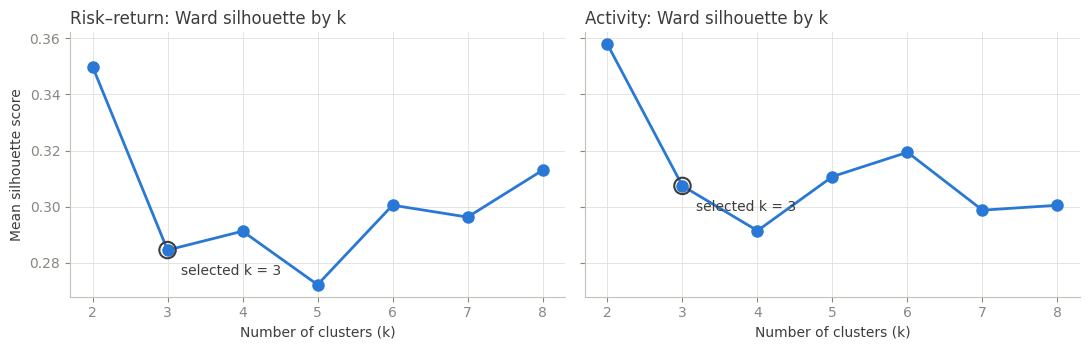

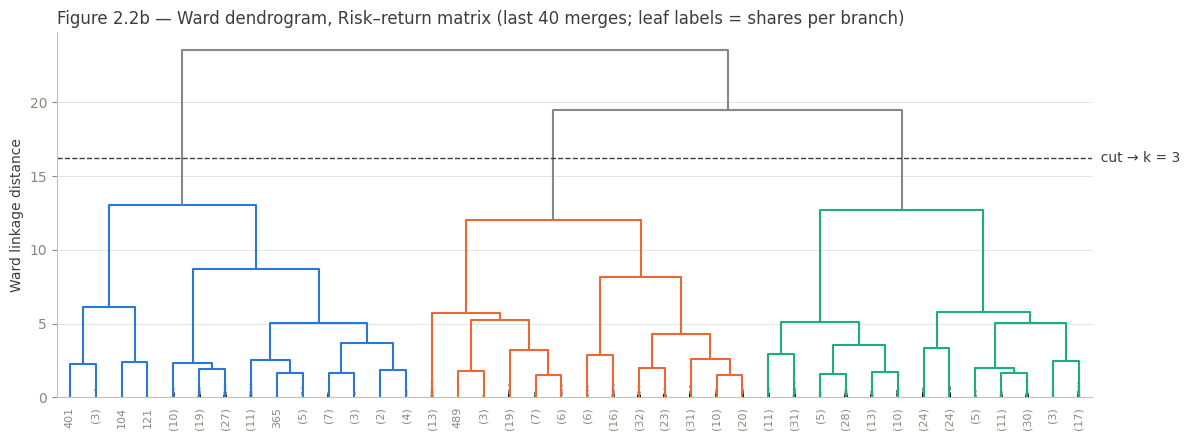

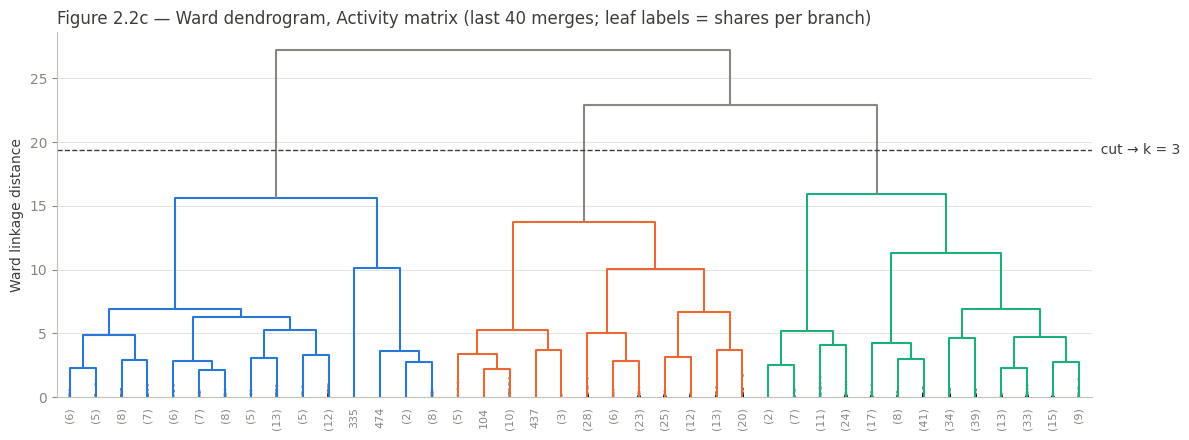


Sensitivity — Activity Ward (k = 3) with log1p(Recency) vs raw Recency: ARI = 0.897


In [53]:
# TASK 2.2: Agglomerative Clustering
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MUTED, GRID, AXIS, INK = '#898781', '#e1e0d9', '#c3c2b7', '#3d3d3a'
plt.rcParams.update({'axes.edgecolor': AXIS, 'axes.labelcolor': INK, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'font.size': 10})

K_RANGE  = range(2, 9)
MIN_SIZE = max(10, int(0.02 * len(X_rr)))

# k chosen from silhouette
SELECTED = {'Risk–return': 3, 'Activity': 3}

mats = {'Risk–return': (X_rr, df_rr), 'Activity': (X_act, df_act)}

def relabel_by_size(lab):
    """Arbitrary cluster numbers → 1 = largest cluster (labels have no meaning beyond grouping)."""
    order = pd.Series(lab).value_counts().index
    return pd.Series(lab).map({c: i + 1 for i, c in enumerate(order)}).to_numpy()

def profile(lab, raw, name):
    d = raw.copy(); d['Cluster'] = lab
    if name == 'Risk–return':
        p = d.groupby('Cluster').agg(Shares=('Weekly_Beta', 'size'),
                                     Mean_Weekly_Return_pct=('Mean_Weekly_Return', lambda s: s.mean() * 100),
                                     Median_Beta=('Weekly_Beta', 'median'),
                                     Beta_range=('Weekly_Beta', lambda s: f'{s.min():.2f}–{s.max():.2f}'))
    else:
        p = d.groupby('Cluster').agg(Shares=('Frequency', 'size'),
                                     Median_Recency_days=('Recency_Days', 'median'),
                                     Mean_Frequency=('Frequency', 'mean'),
                                     Median_Monetary_bn=('Monetary_USD', lambda s: s.median() / 1e9))
    p.insert(1, 'Pct_of_shares', p['Shares'] / len(d) * 100)
    sec = features.loc[raw.index, 'GICS Sector'].groupby(lab)
    p['Top sector'] = sec.agg(lambda s: f'{s.mode()[0]} ({(s == s.mode()[0]).mean():.0%})')
    return p

results, Zs, ward_labels = {}, {}, {}
for name, (X, raw) in mats.items():
    Z = linkage(X.values, method='ward', metric='euclidean')
    Zs[name] = Z
    rows = []
    for k in K_RANGE:
        lab = fcluster(Z, k, criterion='maxclust')
        sizes = np.sort(np.bincount(lab)[1:])[::-1]
        rows.append({'k': k, 'Silhouette': silhouette_score(X, lab),
                     'Calinski_Harabasz': calinski_harabasz_score(X, lab),
                     'Davies_Bouldin': davies_bouldin_score(X, lab),
                     'Merge_height_gap': Z[-(k - 1), 2] - Z[-k, 2],   # jump in Ward distance to go from k to k-1
                     'Smallest': int(sizes.min()), 'Largest_pct': sizes.max() / len(X) * 100,
                     'Sizes': ', '.join(map(str, sizes))})
    res = pd.DataFrame(rows).set_index('k')
    usable = res[res['Smallest'] >= MIN_SIZE]
    suggested = int(usable['Silhouette'].idxmax()) if len(usable) else int(res['Silhouette'].idxmax())
    k_sel = SELECTED[name] or suggested
    res['Selected'] = np.where(res.index == k_sel, '◀', '')
    results[name] = (res, k_sel, suggested)

    print(f'\n=== {name} matrix ({X.shape[1]} features, {len(X)} shares) ===')
    print(f'Table 2.2a — Ward diagnostics for k = 2…8 (usable = smallest cluster ≥ {MIN_SIZE} shares)')
    display(res.style.format({'Silhouette': '{:.3f}', 'Calinski_Harabasz': '{:.1f}', 'Davies_Bouldin': '{:.3f}',
                              'Merge_height_gap': '{:.2f}', 'Largest_pct': '{:.1f}%'})
               .highlight_max(subset=['Silhouette', 'Calinski_Harabasz', 'Merge_height_gap'], color='#cde2fb')
               .highlight_min(subset=['Davies_Bouldin'], color='#cde2fb'))
    print(f'Highest silhouette among usable k: {suggested} | Largest merge-height gap: '
          f'{int(res["Merge_height_gap"].idxmax())} | Selected k: {k_sel}')

    # Profiles in original units: selected k and its neighbours, to judge interpretability
    for k in sorted({max(2, k_sel - 1), k_sel, min(8, k_sel + 1)}):
        lab = relabel_by_size(fcluster(Z, k, criterion='maxclust'))
        print(f'\nTable 2.2{"b" if name == "Risk–return" else "c"} — {name} profiles, k = {k}'
              f'{"  (selected)" if k == k_sel else ""}')
        display(profile(lab, raw, name).style.format(precision=2))

    # Final model with sklearn
    final = relabel_by_size(AgglomerativeClustering(n_clusters=k_sel, linkage='ward',
                                                    metric='euclidean').fit_predict(X))
    check = adjusted_rand_score(final, fcluster(Z, k_sel, criterion='maxclust'))
    print(f'Reproducibility: sklearn vs scipy labels ARI = {check:.3f} (1.000 = identical)')
    ward_labels[name] = final

# Figure 2.2a: Silhouette by k
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, (res, k_sel, _)) in zip(axes, results.items()):
    ax.plot(res.index, res['Silhouette'], color=PAL[0], lw=2, marker='o', ms=8, zorder=3)
    ax.scatter([k_sel], [res.loc[k_sel, 'Silhouette']], s=140, facecolor='none', edgecolor=INK, lw=1.5, zorder=4)
    ax.annotate(f'selected k = {k_sel}', (k_sel, res.loc[k_sel, 'Silhouette']), xytext=(10, -18),
                textcoords='offset points', color=INK)
    ax.set_title(f'{name}: Ward silhouette by k', loc='left', color=INK)
    ax.set_xlabel('Number of clusters (k)'); ax.set_xticks(list(K_RANGE))
axes[0].set_ylabel('Mean silhouette score')
plt.tight_layout(); plt.savefig('fig_2_2a_ward_silhouette.png', dpi=200); plt.show()

# Figures 2.2b / 2.2c: One dendrogram per matrix
for i, (name, Z) in enumerate(Zs.items()):
    k_sel = results[name][1]
    cut = (Z[-(k_sel - 1), 2] + Z[-k_sel, 2]) / 2
    set_link_color_palette(PAL[:k_sel])
    fig, ax = plt.subplots(figsize=(12, 4.5))
    dendrogram(Z, truncate_mode='lastp', p=40, show_contracted=True, color_threshold=cut,
               above_threshold_color=MUTED, leaf_rotation=90, leaf_font_size=8, ax=ax)
    ax.axhline(cut, color=INK, ls='--', lw=1)
    ax.text(ax.get_xlim()[1], cut, f'  cut → k = {k_sel}', va='center', color=INK)
    ax.set_title(f'Figure 2.2{"b" if i == 0 else "c"} — Ward dendrogram, {name} matrix '
                 f'(last 40 merges; leaf labels = shares per branch)', loc='left', color=INK)
    ax.set_ylabel('Ward linkage distance'); ax.grid(axis='x', visible=False)
    plt.tight_layout(); plt.savefig(f'fig_2_2{"b" if i == 0 else "c"}_dendrogram_{name[:3].lower()}.png', dpi=200)
    plt.show()

# Sensitivity: Recency raw vs log1p (from 2.1)
k_act = results['Activity'][1]
alt = df_act.copy()
alt['Recency_Days'] = np.log1p(alt['Recency_Days']); alt['Monetary_USD'] = np.log1p(alt['Monetary_USD'])
X_alt = StandardScaler().fit_transform(alt)
lab_alt = AgglomerativeClustering(n_clusters=k_act, linkage='ward').fit_predict(X_alt)
print(f'\nSensitivity — Activity Ward (k = {k_act}) with log1p(Recency) vs raw Recency: '
      f'ARI = {adjusted_rand_score(ward_labels["Activity"], lab_alt):.3f}')

# Save
pd.DataFrame({'Ward_RiskReturn': ward_labels['Risk–return'], 'Ward_Activity': ward_labels['Activity']},
             index=X_rr.index).to_csv('labels_ward.csv')
for name, (res, _, _) in results.items():
    res.to_csv(f'ward_diagnostics_{name[:3].lower()}.csv')


=== Risk–return matrix — K-means (k-means++, n_init = 50, random_state = 42) ===
Table 2.3a — K-means diagnostics for k = 2…8


,Inertia,Silhouette,Smallest,Largest_pct,Sizes,Single_start_worse_pct,Single_start_mean_ARI,Selected
k,,,,,,,,
2,629.4,0.390,146,70.4%,"348, 146",0%,1.000,
3,476.6,0.319,121,41.9%,"207, 166, 121",5%,0.948,◀
4,375.6,0.324,40,34.0%,"168, 161, 125, 40",100%,0.653,
5,314.3,0.337,23,30.4%,"150, 136, 130, 55, 23",100%,0.540,
6,262.1,0.338,7,32.6%,"161, 127, 106, 53, 40, 7",100%,0.489,
7,226.5,0.332,7,28.9%,"143, 92, 86, 75, 51, 40, 7",95%,0.560,
8,194.3,0.353,7,27.7%,"137, 81, 78, 77, 44, 40, 30, 7",100%,0.705,


Highest silhouette among usable k: 2 | Inertia elbow: 4 | Selected k: 3

Table 2.3b — Risk–return K-means profiles, k = 2


,Shares,Pct_of_shares,Mean_Weekly_Return_pct,Median_Beta,Beta_range,Top sector
Cluster,,,,,,
1,348,70.45,0.19,0.84,0.06–1.84,Financials (16%)
2,146,29.55,0.55,1.28,0.59–3.78,Information Technology (33%)



Table 2.3b — Risk–return K-means profiles, k = 3  (selected)


,Shares,Pct_of_shares,Mean_Weekly_Return_pct,Median_Beta,Beta_range,Top sector
Cluster,,,,,,
1,207,41.90,0.26,0.63,0.06–0.99,Financials (16%)
2,166,33.60,0.10,1.08,0.56–2.50,Information Technology (19%)
3,121,24.49,0.61,1.23,0.59–3.78,Information Technology (32%)


... (10 outputs left out)


Table 2.3b — Activity K-means profiles, k = 4


,Shares,Pct_of_shares,Median_Recency_days,Mean_Frequency,Median_Monetary_bn,Top sector
Cluster,,,,,,
1,214,43.32,11.00,2.37,13.35,Industrials (21%)
2,124,25.10,11.00,4.55,12.83,Industrials (20%)
3,95,19.23,11.00,3.27,60.18,Information Technology (26%)
4,61,12.35,56.00,1.64,21.24,Information Technology (21%)


Reproducibility (k = 3): same seed rerun ARI = 1.000 | 5 other seeds ARI min = 0.993, mean = 0.997

Table 2.3c — Activity: within-cluster std of each standardised feature (k = 3)


,Recency_Days,Frequency,log1p_Monetary,Shares,Spread ratio (max/min std)
1,0.34,0.93,0.50,274,2.74
2,0.42,0.94,0.81,155,2.24
3,1.34,0.78,0.91,65,1.72


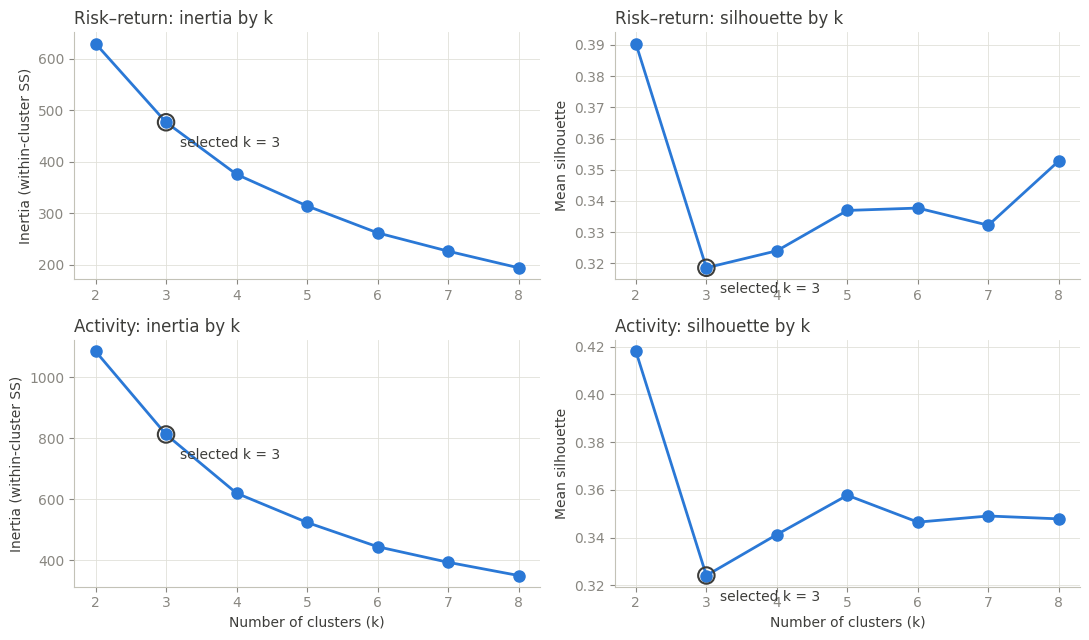

In [54]:
# TASK 2.3: K-Means Clustering
from sklearn.cluster import KMeans

SEED, N_INIT, N_SINGLE = 42, 50, 20

# k chosen from silhouette
SELECTED_KM = {'Risk–return': 3, 'Activity': 3}

def elbow_k(inertia):
    """k furthest from the straight line joining the first and last points of the inertia curve."""
    k = np.array(inertia.index, dtype=float); y = inertia.values
    xn, yn = (k - k.min()) / (k.max() - k.min()), (y - y.min()) / (y.max() - y.min())
    d = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return int(k[np.argmax(d)])

km_results, km_labels = {}, {}
for name, (X, raw) in mats.items():
    rows = []
    for k in K_RANGE:
        km  = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        lab = km.labels_
        sizes = np.sort(np.bincount(lab))[::-1]
        single = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(X) for s in range(N_SINGLE)]
        in1 = np.array([m.inertia_ for m in single])
        rows.append({'k': k, 'Inertia': km.inertia_, 'Silhouette': silhouette_score(X, lab),
                     'Smallest': int(sizes.min()), 'Largest_pct': sizes.max() / len(X) * 100,
                     'Sizes': ', '.join(map(str, sizes)),
                     'Single_start_worse_pct': (in1 > km.inertia_ * 1.0001).mean() * 100,
                     'Single_start_mean_ARI': np.mean([adjusted_rand_score(lab, m.labels_) for m in single])})
    res = pd.DataFrame(rows).set_index('k')
    usable = res[res['Smallest'] >= MIN_SIZE]
    sil_k   = int(usable['Silhouette'].idxmax()) if len(usable) else int(res['Silhouette'].idxmax())
    elb_k   = elbow_k(res['Inertia'])
    k_sel   = SELECTED_KM[name] or sil_k
    res['Selected'] = np.where(res.index == k_sel, '◀', '')
    km_results[name] = (res, k_sel)

    print(f'\n=== {name} matrix — K-means (k-means++, n_init = {N_INIT}, random_state = {SEED}) ===')
    print('Table 2.3a — K-means diagnostics for k = 2…8')
    display(res.style.format({'Inertia': '{:.1f}', 'Silhouette': '{:.3f}', 'Largest_pct': '{:.1f}%',
                              'Single_start_worse_pct': '{:.0f}%', 'Single_start_mean_ARI': '{:.3f}'})
               .highlight_max(subset=['Silhouette'], color='#cde2fb'))
    print(f'Highest silhouette among usable k: {sil_k} | Inertia elbow: {elb_k} | Selected k: {k_sel}')

    # Profiles in original units (selected k and neighbours)
    final = relabel_by_size(KMeans(n_clusters=k_sel, n_init=N_INIT, random_state=SEED).fit_predict(X))
    for k in sorted({max(2, k_sel - 1), k_sel, min(8, k_sel + 1)}):
        lab = relabel_by_size(KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit_predict(X))
        print(f'\nTable 2.3b — {name} K-means profiles, k = {k}{"  (selected)" if k == k_sel else ""}')
        display(profile(lab, raw, name).style.format(precision=2))

    # Reproducibility
    again = KMeans(n_clusters=k_sel, n_init=N_INIT, random_state=SEED).fit_predict(X)
    other = [adjusted_rand_score(final, KMeans(n_clusters=k_sel, n_init=N_INIT, random_state=s).fit_predict(X))
             for s in [0, 1, 7, 123, 2024]]
    print(f'Reproducibility (k = {k_sel}): same seed rerun ARI = {adjusted_rand_score(final, again):.3f} | '
          f'5 other seeds ARI min = {min(other):.3f}, mean = {np.mean(other):.3f}')

    # Table 2.3c: K-Means assumptions
    Xd = pd.DataFrame(X, index=raw.index, columns=X.columns if hasattr(X, 'columns') else None)
    spread = Xd.groupby(final).std(ddof=0)
    spread['Shares'] = pd.Series(final).value_counts().sort_index().values
    spread['Spread ratio (max/min std)'] = spread.drop(columns='Shares').max(axis=1) / spread.drop(columns='Shares').min(axis=1)
    print(f'\nTable 2.3c — {name}: within-cluster std of each standardised feature (k = {k_sel})')
    display(spread.style.format(precision=2))
    km_labels[name] = final

# Figure 2.3a: Inertia (elbow) and silhouette by k
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for r, (name, (res, k_sel)) in enumerate(km_results.items()):
    for c, (col, lab_y) in enumerate([('Inertia', 'Inertia (within-cluster SS)'), ('Silhouette', 'Mean silhouette')]):
        ax = axes[r, c]
        ax.plot(res.index, res[col], color=PAL[0], lw=2, marker='o', ms=8, zorder=3)
        ax.scatter([k_sel], [res.loc[k_sel, col]], s=140, facecolor='none', edgecolor=INK, lw=1.5, zorder=4)
        ax.annotate(f'selected k = {k_sel}', (k_sel, res.loc[k_sel, col]), xytext=(10, -18),
                    textcoords='offset points', color=INK)
        ax.set_title(f'{name}: {col.lower()} by k', loc='left', color=INK)
        ax.set_xticks(list(K_RANGE)); ax.set_ylabel(lab_y)
        if r == 1: ax.set_xlabel('Number of clusters (k)')
plt.tight_layout(); plt.savefig('fig_2_3a_kmeans_elbow_silhouette.png', dpi=200); plt.show()

# Save
pd.DataFrame({'KMeans_RiskReturn': km_labels['Risk–return'], 'KMeans_Activity': km_labels['Activity']},
             index=X_rr.index).to_csv('labels_kmeans.csv')
for name, (res, _) in km_results.items():
    res.to_csv(f'kmeans_diagnostics_{name[:3].lower()}.csv')


Table 2.4a — Risk–return cluster profiles in original units (k = 3)



Table 2.4a — Activity cluster profiles in original units (k = 3)



Table 2.4b — Ward vs K-means on the same 494 shares (sizes in the order of Table 2.4a)


,Shares compared,Same shares,ARI (Ward vs K-means),Same named cluster,Shares that switch,Silhouette Ward,Silhouette K-means,Sizes Ward,Sizes K-means
Matrix,,,,,,,,,
Risk–return,494,True,0.588,84.8%,75,0.285,0.319,"212, 187, 95","207, 166, 121"
Activity,494,True,0.829,93.1%,34,0.307,0.324,"253, 147, 94","274, 155, 65"



Table 2.4c — Risk–return: cross-tabulation (diagonal = agreement)


K-means,Defensive (low beta),Market-like,High return
Ward,,,
Defensive (low beta),182,18,12
Market-like,25,145,17
High return,0,3,92


Examples of shares that switch: AKAM (Defensive (low beta) → Market-like), AMAT (Market-like → High return), AMD (Market-like → High return), AME (Market-like → Defensive (low beta)), AMT (Defensive (low beta) → Market-like), AWK (Defensive (low beta) → Market-like), BAX (Defensive (low beta) → Market-like), BE (Market-like → High return)

Table 2.4c — Activity: cross-tabulation (diagonal = agreement)


K-means,Typical activity,High traded value,Quiet (stale activity)
Ward,,,
Typical activity,253,0,0
High traded value,5,142,0
Quiet (stale activity),16,13,65


Examples of shares that switch: ALL (Quiet (stale activity) → Typical activity), BBY (Quiet (stale activity) → Typical activity), CME (Quiet (stale activity) → High traded value), CRWD (Quiet (stale activity) → High traded value), CVNA (Quiet (stale activity) → High traded value), DDOG (Quiet (stale activity) → High traded value), DE (Quiet (stale activity) → High traded value), DELL (Quiet (stale activity) → High traded value)

Table 2.4d — PCA of standardised activity features: PC1 45.7%, PC2 33.8%, total 79.5% of variance shown; 20.5% not visible in 2-D


,PC1,PC2
Recency_Days,0.71,0.03
Frequency,-0.64,0.43
log1p_Monetary,0.28,0.90


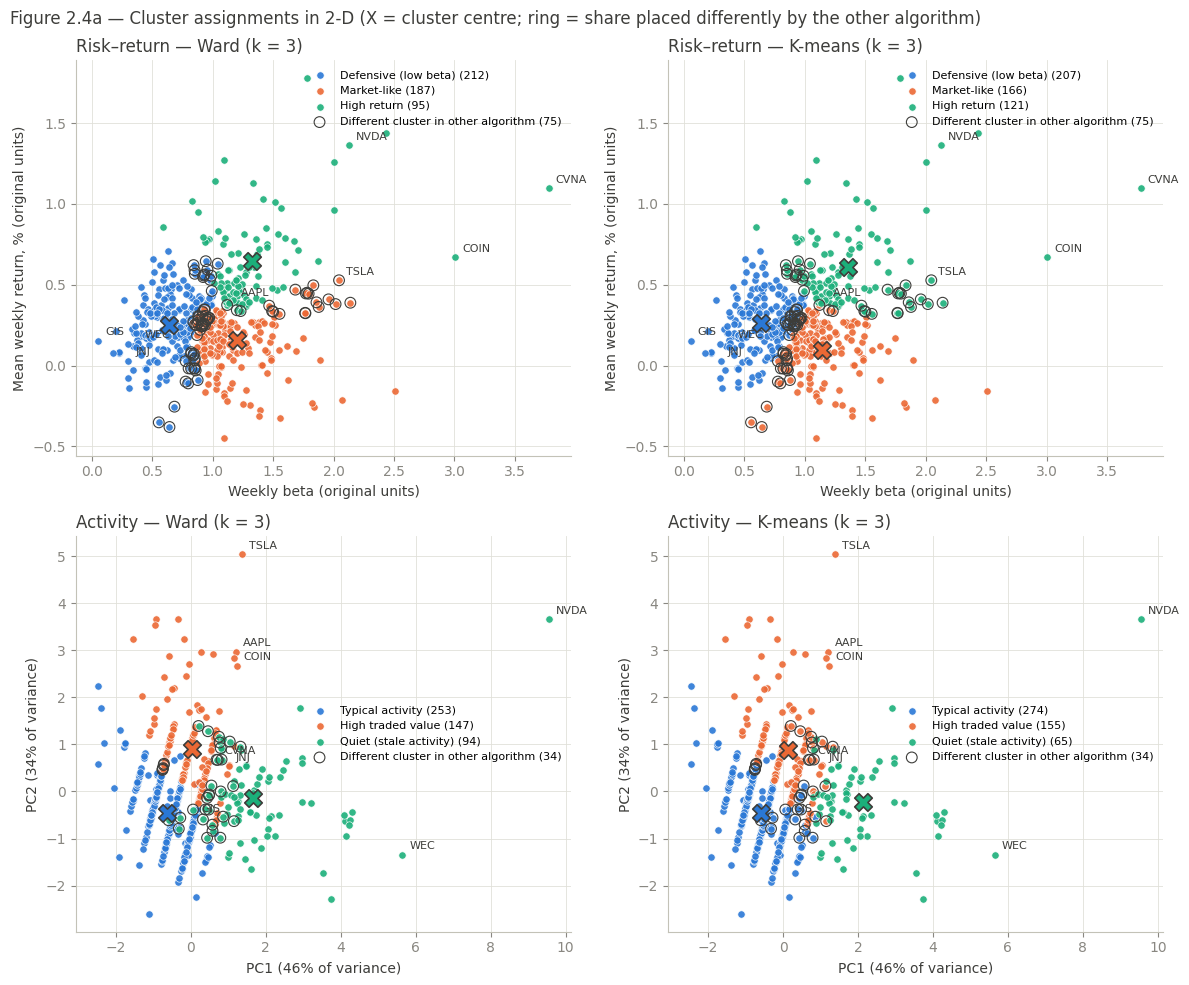

In [55]:
# TASK 2.4: Cluster Profiles and Algorithm Comparison
from sklearn.decomposition import PCA

ORDER = {'Risk–return': ['Defensive (low beta)', 'Market-like', 'High return'],
         'Activity':    ['Typical activity', 'High traded value', 'Quiet (stale activity)']}
COLOR = {n: PAL[i] for names in ORDER.values() for i, n in enumerate(names)}

def name_clusters(lab, raw, kind):
    """Cluster numbers are arbitrary — name each cluster from its profile so algorithms can be matched."""
    d = raw.copy(); d['c'] = lab; names = {}
    if kind == 'Risk–return':
        g = d.groupby('c').agg(b=('Weekly_Beta', 'median'), r=('Mean_Weekly_Return', 'mean'))
        hi = g['r'].idxmax(); names[hi] = 'High return'
        rest = g.drop(hi); lo = rest['b'].idxmin(); names[lo] = 'Defensive (low beta)'
        for c in rest.index.drop(lo): names[c] = 'Market-like'
    else:
        g = d.groupby('c').agg(R=('Recency_Days', 'median'), M=('Monetary_USD', 'median'))
        q = g['R'].idxmax(); names[q] = 'Quiet (stale activity)'
        rest = g.drop(q); h = rest['M'].idxmax(); names[h] = 'High traded value'
        for c in rest.index.drop(h): names[c] = 'Typical activity'
    return pd.Series(lab, index=raw.index).map(names)

sol = {}
for name, (X, raw) in mats.items():
    sol[(name, 'Ward')]    = name_clusters(ward_labels[name], raw, name)
    sol[(name, 'K-means')] = name_clusters(km_labels[name],   raw, name)

# Table 2.4a: Profiles in original units, both algorithms
for name, (X, raw) in mats.items():
    tabs = {alg: profile(sol[(name, alg)], raw, name).reindex(ORDER[name]) for alg in ['Ward', 'K-means']}
    t = pd.concat(tabs, names=['Algorithm', 'Cluster'])
    print(f'\nTable 2.4a — {name} cluster profiles in original units (k = 3)')
    display(t.style.format(precision=2))

# Table 2.4b: Algorithm comparison on the same shares
rows = []
for name, (X, raw) in mats.items():
    w, k = sol[(name, 'Ward')], sol[(name, 'K-means')]
    rows.append({'Matrix': name, 'Shares compared': len(w), 'Same shares': bool(w.index.equals(k.index)),
                 'ARI (Ward vs K-means)': adjusted_rand_score(w, k),
                 'Same named cluster': (w == k).mean(), 'Shares that switch': int((w != k).sum()),
                 'Silhouette Ward': silhouette_score(X, w), 'Silhouette K-means': silhouette_score(X, k),
                 'Sizes Ward': ', '.join(str(int((w == n).sum())) for n in ORDER[name]),
                 'Sizes K-means': ', '.join(str(int((k == n).sum())) for n in ORDER[name])})
cmp_tab = pd.DataFrame(rows).set_index('Matrix')
print('\nTable 2.4b — Ward vs K-means on the same 494 shares (sizes in the order of Table 2.4a)')
display(cmp_tab.style.format({'ARI (Ward vs K-means)': '{:.3f}', 'Same named cluster': '{:.1%}',
                              'Silhouette Ward': '{:.3f}', 'Silhouette K-means': '{:.3f}'}))

# Table 2.4c: Algorithm Disagreement
for name in mats:
    w, k = sol[(name, 'Ward')], sol[(name, 'K-means')]
    ct = pd.crosstab(w, k, rownames=['Ward'], colnames=['K-means']).reindex(index=ORDER[name], columns=ORDER[name])
    print(f'\nTable 2.4c — {name}: cross-tabulation (diagonal = agreement)')
    display(ct)
    sw = pd.DataFrame({'Ward': w, 'K-means': k})[w != k]
    print(f'Examples of shares that switch: ' +
          ', '.join(f'{t} ({a} → {b})' for t, (a, b) in sw.head(8).iterrows()))

# Table 2.4d: PCA for the 3-feature activity matrix
pca = PCA(n_components=2, random_state=SEED).fit(X_act)
P = pd.DataFrame(pca.transform(X_act), index=X_act.index, columns=['PC1', 'PC2'])
evr = pca.explained_variance_ratio_
load = pd.DataFrame(pca.components_.T, index=X_act.columns, columns=['PC1', 'PC2'])
print(f'\nTable 2.4d — PCA of standardised activity features: PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, '
      f'total {evr.sum():.1%} of variance shown; {1 - evr.sum():.1%} not visible in 2-D')
display(load.style.format('{:.2f}').background_gradient(cmap='RdBu', vmin=-1, vmax=1))

# Figure 2.4a: Labelled 2-D views for both algorithms
LABEL_T = [t for t in ['AAPL', 'NVDA', 'TSLA', 'CVNA', 'COIN', 'GIS', 'JNJ', 'WEC'] if t in X_rr.index]
views = {'Risk–return': (df_rr['Weekly_Beta'], df_rr['Mean_Weekly_Return'] * 100,
                         'Weekly beta (original units)', 'Mean weekly return, % (original units)'),
         'Activity': (P['PC1'], P['PC2'], f'PC1 ({evr[0]:.0%} of variance)', f'PC2 ({evr[1]:.0%} of variance)')}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for r, name in enumerate(mats):
    xs, ys, xl, yl = views[name]
    other = {'Ward': sol[(name, 'K-means')], 'K-means': sol[(name, 'Ward')]}
    for c, alg in enumerate(['Ward', 'K-means']):
        ax, lab = axes[r, c], sol[(name, alg)]
        for n in ORDER[name]:
            m = lab == n
            ax.scatter(xs[m], ys[m], s=28, color=COLOR[n], edgecolor='white', lw=0.5, alpha=0.9,
                       label=f'{n} ({int(m.sum())})', zorder=2)
            ax.scatter(xs[m].mean(), ys[m].mean(), s=160, marker='X', color=COLOR[n], edgecolor=INK, lw=1.2, zorder=4)
        diff = lab != other[alg]
        ax.scatter(xs[diff], ys[diff], s=60, facecolor='none', edgecolor=INK, lw=0.8, zorder=3,
                   label=f'Different cluster in other algorithm ({int(diff.sum())})')
        for t in LABEL_T:
            ax.annotate(t, (xs[t], ys[t]), xytext=(5, 4), textcoords='offset points', fontsize=8, color=INK)
        ax.set_title(f'{name} — {alg} (k = 3)', loc='left', color=INK)
        ax.set_xlabel(xl); ax.set_ylabel(yl)
        ax.legend(fontsize=8, frameon=False, loc='best')
fig.suptitle('Figure 2.4a — Cluster assignments in 2-D (X = cluster centre; ring = share placed differently by the other algorithm)',
             x=0.01, ha='left', color=INK)
plt.tight_layout(); plt.savefig('fig_2_4a_cluster_views.png', dpi=200); plt.show()

# Save
pd.DataFrame({f'{a}_{m[:3]}': sol[(m, a)] for (m, a) in sol}).to_csv('labels_named_all_solutions.csv')
cmp_tab.to_csv('algorithm_comparison.csv'); load.to_csv('pca_loadings_activity.csv')

In [56]:
# TASK 2.5.1: Correlation Analysis
from scipy.stats import pearsonr, spearmanr

C = df_act_t.rename(columns={'Recency_Days': 'R', 'Frequency': 'F', 'log1p_Monetary': 'log1p(M)'})
Xs = X_act.rename(columns={'Recency_Days': 'R', 'Frequency': 'F', 'log1p_Monetary': 'log1p(M)'})

# Table 2.5.1a: Pairwise correlations
pairs = [('R', 'F'), ('R', 'log1p(M)'), ('F', 'log1p(M)')]
rows = []
for a, b in pairs:
    r, pr = pearsonr(C[a], C[b]); rho, ps = spearmanr(C[a], C[b])
    rows.append({'Pair': f'{a} – {b}', 'Pearson r': r, 'p (Pearson)': pr,
                 'Spearman ρ': rho, 'p (Spearman)': ps, 'Shared variance r²': r**2})
corr_tab = pd.DataFrame(rows).set_index('Pair')
print('Table 2.5.1a — Correlations among R, F and log1p(M) (494 shares)')
display(corr_tab.style.format({'Pearson r': '{:.3f}', 'Spearman ρ': '{:.3f}', 'Shared variance r²': '{:.1%}',
                               'p (Pearson)': '{:.2g}', 'p (Spearman)': '{:.2g}'}))
print('Correlation matrix (Pearson):'); display(C.corr().style.format('{:.2f}')
                                              .background_gradient(cmap='RdBu', vmin=-1, vmax=1))

# Standardisation does not remove correlation
same = np.allclose(C.corr().values, Xs.corr().values)
print(f'Correlations identical before and after standardisation: {same} '
      f'(scaling equalises each feature’s spread, not the overlap between features)')

# Table 2.5.1b: Shared direction counted twice?
eig = np.sort(np.linalg.eigvalsh(C.corr().values))[::-1]
eig_tab = pd.DataFrame({'Eigenvalue': eig, 'Share of total variance': eig / eig.sum(),
                        'If features were uncorrelated': [1.0, 1.0, 1.0]},
                       index=['Direction 1', 'Direction 2', 'Direction 3'])
print('\nTable 2.5.1b — Eigenvalues of the R/F/log1p(M) correlation matrix '
      '(1.0 each = no overlap; one large value = repeated influence)')
display(eig_tab.style.format({'Eigenvalue': '{:.3f}', 'Share of total variance': '{:.1%}',
                              'If features were uncorrelated': '{:.1f}'}))
print(f'Effective number of independent directions (Σλ)² / Σλ²: {eig.sum()**2 / (eig**2).sum():.2f} of 3')

# Table 2.5.1c: Feature that separates the clusters
def feature_separation(X, lab):
    g = X.groupby(lab); n = g.size(); m = g.mean()
    bss = (m**2).mul(n, axis=0).sum()
    tss = (X**2).sum()
    return pd.DataFrame({'Between-cluster SS': bss, 'Share of separation': bss / bss.sum(),
                         'Variance explained (R²)': bss / tss})
sep = pd.concat({'Ward (k = 3)':    feature_separation(Xs, ward_labels['Activity']),
                 'K-means (k = 3)': feature_separation(Xs, km_labels['Activity'])})
print('\nTable 2.5.1c — Contribution of each standardised feature to between-cluster distance')
display(sep.style.format({'Between-cluster SS': '{:.1f}', 'Share of separation': '{:.1%}',
                          'Variance explained (R²)': '{:.1%}'}))
print('Equal influence would be 33.3% each. Correlation (2.5.1a) shows overlap; this table shows influence.')

# Save
corr_tab.to_csv('rfm_correlations.csv'); eig_tab.to_csv('rfm_correlation_eigenvalues.csv')
sep.to_csv('rfm_feature_separation.csv')

Table 2.5.1a — Correlations among R, F and log1p(M) (494 shares)


,Pearson r,p (Pearson),Spearman ρ,p (Spearman),Shared variance r²
Pair,,,,,
R – F,-0.341,6e-15,-0.190,2.1e-05,11.7%
R – log1p(M),0.163,0.00026,0.154,0.00058,2.7%
F – log1p(M),0.019,0.68,-0.042,0.35,0.0%


Correlation matrix (Pearson):


,R,F,log1p(M)
R,1.00,-0.34,0.16
F,-0.34,1.00,0.02
log1p(M),0.16,0.02,1.00


Correlations identical before and after standardisation: True (scaling equalises each feature’s spread, not the overlap between features)

Table 2.5.1b — Eigenvalues of the R/F/log1p(M) correlation matrix (1.0 each = no overlap; one large value = repeated influence)


,Eigenvalue,Share of total variance,If features were uncorrelated
Direction 1,1.371,45.7%,1.0
Direction 2,1.015,33.8%,1.0
Direction 3,0.614,20.5%,1.0


Effective number of independent directions (Σλ)² / Σλ²: 2.74 of 3

Table 2.5.1c — Contribution of each standardised feature to between-cluster distance


Equal influence would be 33.3% each. Correlation (2.5.1a) shows overlap; this table shows influence.


Shares: 494 (same as full: True) | k = 3 | reduced matrix scaled afresh — means [-0.0, 0.0], std [1.0, 1.0]

ARI (full R+F+log M  vs  R+F only): 0.329
Random-label baseline ARI: mean 0.001, 95th percentile 0.016 → 1.000 = identical memberships, ≈0 = no more agreement than chance

Table 2.5.2a — Full Ward clusters (rows) vs R+F-only Ward clusters (columns)


"Reduced (R, F)",Less frequent (R+F),More frequent (R+F),Quiet (R+F)
"Full (R, F, log M)",,,
Typical activity,66,186,1
High traded value,59,87,1
Quiet (stale activity),0,3,91



Table 2.5.2b — Traded value profiles (original units)



Table 2.5.2c — Share of each feature’s variation explained by the clusters (R²)


,"Full (R, F, log M)","Reduced (R, F)",Change
R,63.4%,64.5%,1.1%
F,13.2%,53.7%,40.5%
log1p(M),51.9%,0.6%,-51.2%



"High traded value" shares (full solution) in the reduced solution: More frequent (R+F): 87, Less frequent (R+F): 59, Quiet (R+F): 1


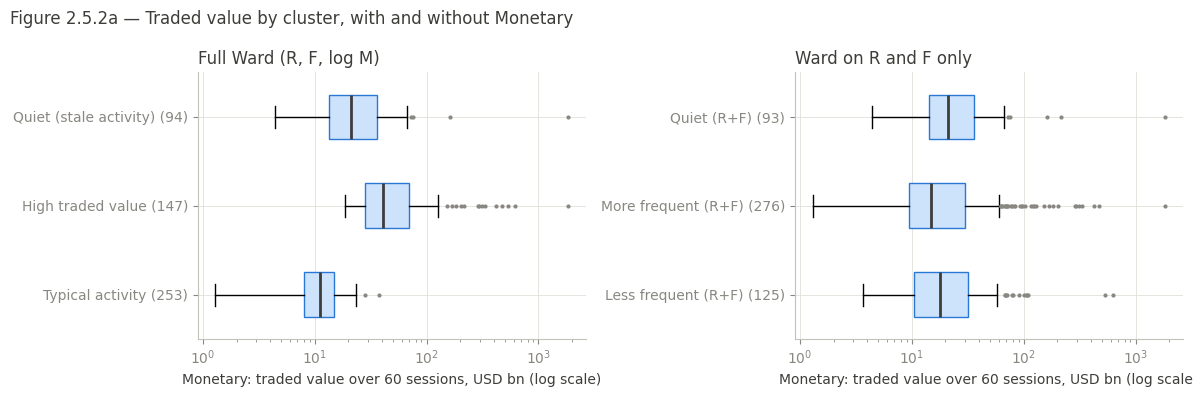

In [57]:
# TASK 2.5.2: Removal of Monetary

K_FULL = results['Activity'][1]
RF = df_act[['Recency_Days', 'Frequency']].copy()
assert RF.index.equals(df_act.index)

# Standardise the reduced matrix AFRESH and refit Ward
sc_rf = StandardScaler()
X_rf = pd.DataFrame(sc_rf.fit_transform(RF), index=RF.index, columns=RF.columns)
lab_rf = relabel_by_size(AgglomerativeClustering(n_clusters=K_FULL, linkage='ward',
                                                 metric='euclidean').fit_predict(X_rf))
lab_full = ward_labels['Activity']

print(f'Shares: {len(X_rf)} (same as full: {X_rf.index.equals(X_act.index)}) | k = {K_FULL} | '
      f'reduced matrix scaled afresh — means {X_rf.mean().round(6).tolist()}, std {X_rf.std(ddof=0).round(6).tolist()}')

# Membership comparison: ARI with a random baseline
ari = adjusted_rand_score(lab_full, lab_rf)
rng = np.random.default_rng(SEED)
null = np.array([adjusted_rand_score(lab_full, rng.permutation(lab_rf)) for _ in range(500)])
print(f'\nARI (full R+F+log M  vs  R+F only): {ari:.3f}')
print(f'Random-label baseline ARI: mean {null.mean():.3f}, 95th percentile {np.percentile(null, 95):.3f} '
      f'→ 1.000 = identical memberships, ≈0 = no more agreement than chance')

# Name reduced clusters from their R/F profile
d = RF.assign(c=lab_rf).groupby('c').agg(R=('Recency_Days', 'median'), F=('Frequency', 'mean'))
q = d['R'].idxmax(); rest = d.drop(q); hf = rest['F'].idxmax()
rf_names = {q: 'Quiet (R+F)', hf: 'More frequent (R+F)'}
rf_names.update({c: 'Less frequent (R+F)' for c in rest.index.drop(hf)})
named_rf = pd.Series(lab_rf, index=RF.index).map(rf_names)
named_full = sol[('Activity', 'Ward')]

# Table 2.5.2a: Full Clusters
print('\nTable 2.5.2a — Full Ward clusters (rows) vs R+F-only Ward clusters (columns)')
display(pd.crosstab(named_full, named_rf, rownames=['Full (R, F, log M)'], colnames=['Reduced (R, F)'])
          .reindex(ORDER['Activity']))

# Table 2.5.2b: Traded value profiles
def tv_profile(lab):
    g = df_act.assign(c=lab).groupby('c')
    return pd.DataFrame({'Shares': g.size(),
                         'Median_Recency_days': g['Recency_Days'].median(),
                         'Mean_Frequency': g['Frequency'].mean(),
                         'Median_Monetary_bn': g['Monetary_USD'].median() / 1e9,
                         'Monetary_IQR_bn': g['Monetary_USD'].apply(lambda s: f'{s.quantile(.25)/1e9:,.1f}–{s.quantile(.75)/1e9:,.1f}'),
                         'Max_Monetary_bn': g['Monetary_USD'].max() / 1e9})
tv = pd.concat({'Full (R, F, log M)': tv_profile(named_full).reindex(ORDER['Activity']),
                'Reduced (R, F)':     tv_profile(named_rf)})
print('\nTable 2.5.2b — Traded value profiles (original units)')
display(tv.style.format({'Median_Recency_days': '{:.0f}', 'Mean_Frequency': '{:.2f}',
                         'Median_Monetary_bn': '{:,.1f}', 'Max_Monetary_bn': '{:,.1f}'}))

# Table 2.5.2c: Features each solution separates
Xfull = X_act.rename(columns={'Recency_Days': 'R', 'Frequency': 'F', 'log1p_Monetary': 'log1p(M)'})
r2 = pd.DataFrame({'Full (R, F, log M)': feature_separation(Xfull, lab_full)['Variance explained (R²)'],
                   'Reduced (R, F)':     feature_separation(Xfull, lab_rf)['Variance explained (R²)']})
r2['Change'] = r2['Reduced (R, F)'] - r2['Full (R, F, log M)']
print('\nTable 2.5.2c — Share of each feature’s variation explained by the clusters (R²)')
display(r2.style.format('{:.1%}'))

# High-traded-value shares without M
htv = named_full == 'High traded value'
print('\n"High traded value" shares (full solution) in the reduced solution: ' +
      ', '.join(f'{n}: {c}' for n, c in named_rf[htv].value_counts().items()))

# Figure 2.5.2a: Traded value by cluster (with and without M)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, (title, lab, order) in zip(axes, [('Full Ward (R, F, log M)', named_full, ORDER['Activity']),
                                          ('Ward on R and F only', named_rf, sorted(named_rf.unique()))]):
    data = [df_act.loc[lab == n, 'Monetary_USD'] / 1e9 for n in order]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.5, showfliers=True,
                    medianprops=dict(color=INK, lw=2), flierprops=dict(marker='o', ms=3, mfc=MUTED, mec='none'))
    for b in bp['boxes']: b.set(facecolor='#cde2fb', edgecolor=PAL[0])
    ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels([f'{n} ({int((lab == n).sum())})' for n in order])
    ax.set_xscale('log'); ax.set_xlabel('Monetary: traded value over 60 sessions, USD bn (log scale)')
    ax.set_title(title, loc='left', color=INK)
fig.suptitle('Figure 2.5.2a — Traded value by cluster, with and without Monetary', x=0.01, ha='left', color=INK)
plt.tight_layout(); plt.savefig('fig_2_5_2a_traded_value_profiles.png', dpi=200); plt.show()

# Save
pd.DataFrame({'Ward_full': named_full, 'Ward_RF_only': named_rf}).to_csv('labels_monetary_removal.csv')
tv.to_csv('monetary_removal_profiles.csv'); r2.to_csv('monetary_removal_r2.csv')

In [58]:
# TASK 3 Business Intelligence and Critical Review

Table 3.2.1a — Ward cluster profiles on both dimensions (original units)



Table 3.2.1b — Sector composition: % of each cluster (columns sum to 100%)



Table 3.2.1c — Strength of association (Cramér’s V: 0 = none, 1 = perfect)


,Cramér's V,p-value,Cells with expected count < 5
Clustering,,,
Risk–return – Ward,0.377,3.6e-20,9%
Risk–return – K-means,0.370,4.3e-19,0%
Activity – Ward,0.256,1.4e-06,9%
Activity – K-means,0.264,2.8e-07,18%
Risk–return vs Activity (Ward),0.097,0.055,0%


ARI risk–return vs activity clusters (Ward): 0.015


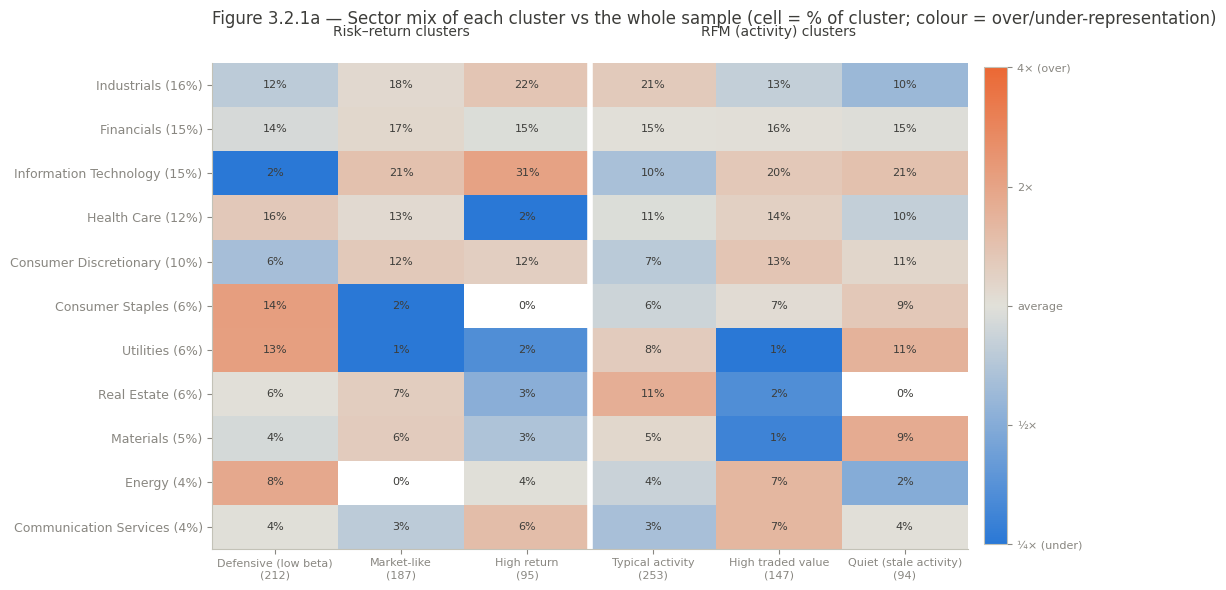

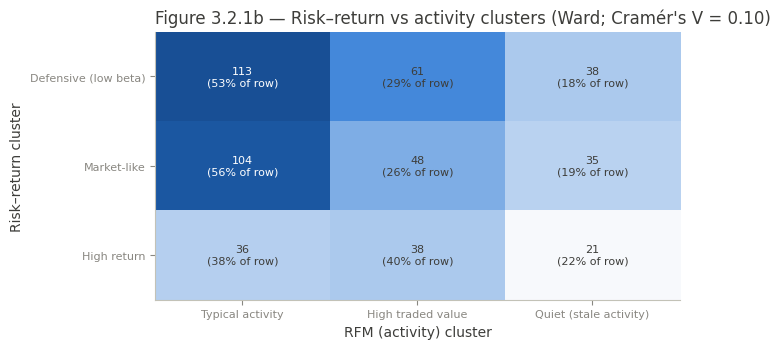

In [59]:
# TASK 3.2: Review of results and visualisation
# TASK 3.2.1: Cluster profiles and sector composition

from scipy.stats import chi2_contingency
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

rr_lab, act_lab = sol[('Risk–return', 'Ward')], sol[('Activity', 'Ward')]
base   = features.loc[rr_lab.index]
sector = base['GICS Sector']

def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2, p, dof, exp = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return v, p, (exp < 5).mean()

# Table 3.2.1a: Profiles on both dimensions (original units)
def cross_profile(lab, order):
    g = base.groupby(lab)
    return pd.DataFrame({'Shares': g.size(),
                         'Mean weekly return %': g['Mean_Weekly_Return'].mean() * 100,
                         'Median beta': g['Weekly_Beta'].median(),
                         'Median R (days)': g['Recency_Days'].median(),
                         'Mean F (days)': g['Frequency'].mean(),
                         'Median M ($bn)': g['Monetary_USD'].median() / 1e9}).reindex(order)
prof = pd.concat({'Risk–return clusters': cross_profile(rr_lab, ORDER['Risk–return']),
                  'RFM (activity) clusters': cross_profile(act_lab, ORDER['Activity'])})
print('Table 3.2.1a — Ward cluster profiles on both dimensions (original units)')
display(prof.style.format({'Mean weekly return %': '{:.2f}', 'Median beta': '{:.2f}', 'Median R (days)': '{:.0f}',
                           'Mean F (days)': '{:.2f}', 'Median M ($bn)': '{:,.1f}'}))

# Table 3.2.1b: Sector composition of each cluster
overall = sector.value_counts(normalize=True)
sec_order = overall.index
comp = {name: pd.crosstab(sector, lab, normalize='columns').reindex(index=sec_order, columns=ORDER[name]).fillna(0)
        for name, lab in [('Risk–return', rr_lab), ('Activity', act_lab)]}
comp_tab = pd.concat(comp, axis=1)
comp_tab[('All shares', '(494)')] = overall
print('\nTable 3.2.1b — Sector composition: % of each cluster (columns sum to 100%)')
display(comp_tab.style.format('{:.0%}'))

# Association tests
rows = []
for name, alg in [('Risk–return', 'Ward'), ('Risk–return', 'K-means'), ('Activity', 'Ward'), ('Activity', 'K-means')]:
    v, p, small = cramers_v(sector, sol[(name, alg)])
    rows.append({'Clustering': f'{name} – {alg}', "Cramér's V with sector": v, 'p-value': p,
                 'Cells with expected count < 5': small})
v_rr_act, p_rr_act, small_ra = cramers_v(rr_lab, act_lab)
rows.append({'Clustering': 'Risk–return vs Activity (Ward)', "Cramér's V with sector": v_rr_act,
             'p-value': p_rr_act, 'Cells with expected count < 5': small_ra})
assoc = pd.DataFrame(rows).set_index('Clustering').rename(
    columns={"Cramér's V with sector": "Cramér's V"})
print('\nTable 3.2.1c — Strength of association (Cramér’s V: 0 = none, 1 = perfect)')
display(assoc.style.format({"Cramér's V": '{:.3f}', 'p-value': '{:.2g}', 'Cells with expected count < 5': '{:.0%}'}))
print(f'ARI risk–return vs activity clusters (Ward): {adjusted_rand_score(rr_lab, act_lab):.3f}')

# Figure 3.2.1a: Sector over/under-representation heatmap
idx = pd.concat({n: comp[n].div(overall, axis=0) for n in comp}, axis=1)
vals = np.log2(idx.replace(0, np.nan)).clip(-2, 2)
cmap = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#e1e0d9', '#eb6834'])
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(vals.values, cmap=cmap, norm=TwoSlopeNorm(0, -2, 2), aspect='auto')
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        share = comp_tab.iloc[i, j]
        ax.text(j, i, f'{share:.0%}', ha='center', va='center', fontsize=8, color=INK)
ax.set_xticks(range(vals.shape[1]))
ax.set_xticklabels([f'{c}\n({int((rr_lab if m == "Risk–return" else act_lab).eq(c).sum())})' for m, c in vals.columns],
                   fontsize=8)
ax.set_yticks(range(len(sec_order)))
ax.set_yticklabels([f'{s} ({overall[s]:.0%})' for s in sec_order], fontsize=9)
ax.axvline(2.5, color='white', lw=4)
ax.text(1, -1.1, 'Risk–return clusters', ha='center', color=INK); ax.text(4, -1.1, 'RFM (activity) clusters', ha='center', color=INK)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(['¼× (under)', '½×', 'average', '2×', '4× (over)'], fontsize=8)
ax.set_title('Figure 3.2.1a — Sector mix of each cluster vs the whole sample '
             '(cell = % of cluster; colour = over/under-representation)', loc='left', color=INK, pad=28)
plt.tight_layout(); plt.savefig('fig_3_2_1a_sector_heatmap.png', dpi=200); plt.show()

# Figure 3.2.1b: Cluster Overlap
ct = pd.crosstab(rr_lab, act_lab).reindex(index=ORDER['Risk–return'], columns=ORDER['Activity'])
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(ct.values, cmap=LinearSegmentedColormap.from_list('seq', ['#f7f9fc', '#2a78d6', '#184f95']), aspect='auto')
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        n = ct.iloc[i, j]
        ax.text(j, i, f'{n}\n({n / ct.iloc[i].sum():.0%} of row)', ha='center', va='center', fontsize=8,
                color='white' if n > ct.values.max() * 0.6 else INK)
ax.set_xticks(range(3)); ax.set_xticklabels(ORDER['Activity'], fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels(ORDER['Risk–return'], fontsize=8)
ax.set_xlabel('RFM (activity) cluster'); ax.set_ylabel('Risk–return cluster'); ax.grid(False)
ax.set_title(f"Figure 3.2.1b — Risk–return vs activity clusters (Ward; Cramér's V = {v_rr_act:.2f})",
             loc='left', color=INK)
plt.tight_layout(); plt.savefig('fig_3_2_1b_rr_vs_activity.png', dpi=200); plt.show()

# Save
prof.to_csv('table_3_2_1a_cross_profiles.csv'); comp_tab.to_csv('table_3_2_1b_sector_composition.csv')
assoc.to_csv('table_3_2_1c_associations.csv'); ct.to_csv('table_3_2_1d_rr_vs_activity.csv')